# Exploratory Analysis of User Behavior and Seasonal Preferences on Yandex Afisha


- Author: Nila Sisakyan
- Date: August 21, 2026

## Introduction

### Project Goals and Objectives

**Goal:** Identify key insights into changes in ticket purchasing preferences on Yandex Afisha during the transition from summer to autumn in 2024, and test product hypotheses about differences in behavior between mobile and desktop users.

**Objectives:**
1. **Data preprocessing:**
   - Merge data sources, identify and handle missing values, anomalies, outliers, and duplicates.
   - Convert revenue from tenge (KZT) to rubles (RUB) using daily exchange rates and calculate per-unit metrics (revenue per ticket).
   - Extract temporal features (months and seasons).
2. **Exploratory data analysis (EDA):**
   - Analyze seasonal demand changes (summer vs. autumn) by event type, age restriction, and device.
   - Examine daily autumn activity metrics (orders, DAU, average orders per user, and ticket price).
   - Identify popular events, key regions, and the most active ticketing partners.
3. **Statistical analysis (hypothesis testing):**
   - Test whether the mean number of orders per mobile app user is higher than for desktop PC users.
   - Assess whether the mean time between orders differs between mobile and desktop users.
4. **Conclusions:**
   - Develop practical recommendations for product and marketing teams based on confirmed insights and hypotheses.

### Data Description

The study analyzes three datasets covering **June 1–October 31, 2024**:

#### Ticket Order Data (`final_tickets_orders_df.csv`)
* `order_id` — unique order identifier.
* `user_id` — unique user identifier.
* `created_dt_msk` — order creation date (Moscow time).
* `created_ts_msk` — order creation date and time (Moscow time).
* `event_id` — event identifier.
* `cinema_circuit` — cinema chain ('нет', meaning 'none', if not applicable).
* `age_limit` — event age restriction.
* `currency_code` — payment currency (`rub`, `kzt`).
* `device_type_canonical` — device type (`mobile`, `desktop`).
* `revenue` — order revenue.
* `service_name` — ticketing operator (partner) name.
* `tickets_count` — number of tickets purchased.
* `total` — total order amount.
* `days_since_prev` — days since the user's previous purchase (missing for the first purchase).

#### Event Data (`final_tickets_events_df.csv`)
*(Note: movies are excluded from this dataset)*
* `event_id` — unique event identifier.
* `event_name` — event name.
* `event_type_description` — event type description.
* `event_type_main` — main event type (concert, theater performance, etc.).
* `organizers` — event organizer.
* `region_name` — event region name.
* `city_name` — event city name.
* `venue_id` — unique venue identifier.
* `venue_name` — venue name.
* `venue_address` — venue address.

#### Exchange Rate Data (`final_tickets_tenge_df.csv`)
* `nominal` — currency denomination (100 Kazakhstani tenge).
* `data` — exchange rate date.
* `curs` — tenge-to-ruble exchange rate (value of 100 tenge in rubles).
* `cdx` — currency code (`kzt`).

### Project Contents

1. Data loading and exploration
2. Data preprocessing and preparation (cleaning, filtering, currency conversion, and feature generation)
3. Exploratory data analysis (EDA)
   - Order distributions by segment and seasonal changes
   - Autumn user activity and weekly patterns
   - Popular events, regions, and partners
4. Statistical analysis (product hypothesis testing)
5. Overall conclusions and business recommendations

## Data Loading and Preprocessing

We will start by loading the libraries and datasets.
The project uses the following Python libraries for exploratory and statistical analysis:
* `pandas` — the main tool for loading, preprocessing, cleaning, and aggregating data.
* `numpy` — mathematical calculations and multidimensional arrays.
* `matplotlib` and `seaborn` — data visualization.
* `scipy.stats` — statistical tests.
* `phik` — building a correlation matrix.

The datasets will be stored in `orders_df`, `events_df`, and `currency_df`.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st

In [2]:
# Load datasets into variables
orders_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_orders_df.csv')
events_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_events_df.csv')
currency_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')

Explore the datasets by displaying the first rows with `head()` and DataFrame information with `info()`:

In [3]:
# Display the first rows of the DataFrame
orders_df.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


In [4]:
# Display DataFrame information
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  str    
 2   created_dt_msk         290849 non-null  str    
 3   created_ts_msk         290849 non-null  str    
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  str    
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  str    
 8   device_type_canonical  290849 non-null  str    
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  str    
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), str(7)
memory usage: 3

In [5]:
# Display the first rows of the DataFrame
events_df.head()

,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


In [6]:
# Display DataFrame information
events_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   event_id                22427 non-null  int64
 1   event_name              22427 non-null  str  
 2   event_type_description  22427 non-null  str  
 3   event_type_main         22427 non-null  str  
 4   organizers              22427 non-null  str  
 5   region_name             22427 non-null  str  
 6   city_name               22427 non-null  str  
 7   city_id                 22427 non-null  int64
 8   venue_id                22427 non-null  int64
 9   venue_name              22427 non-null  str  
 10  venue_address           22427 non-null  str  
dtypes: int64(3), str(8)
memory usage: 1.9 MB


In [7]:
# Display the first rows of the DataFrame
currency_df.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [8]:
# Display DataFrame information
currency_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    str    
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    str    
dtypes: float64(1), int64(1), str(2)
memory usage: 11.3 KB


### Preliminary Findings from Initial Data Exploration

The initial examination of the three datasets identified the following:

1. **`orders` table**
   - Contains all transaction information. Data types were mostly inferred correctly (`float64`, `int64`, `object`).
   - `created_dt_msk` (date) and `created_ts_msk` (timestamp) were recognized as text (`object`). They need to be converted to `datetime64` during preprocessing.
   - `days_since_prev` (days since the previous purchase) contains missing values. This is reasonable, since the first purchase has no previous purchase. Other columns initially appear complete, but this requires a stricter check in Step 2.
   - Orders use different currencies (`currency_code`), requiring conversion.

2. **`events` table**
   - Contains reference information on events, venues, and regions.
   - Joins to `orders` through the `event_id` key.
   - No missing values; data types were inferred correctly (mostly text categorical features).

3. **`currency` table**
   - A small table of daily tenge exchange rates. `data` (exchange rate date) was recognized as text (`object`) and needs conversion to `datetime` for a correct date-based join with orders.
   - `curs` is quoted for 100 tenge.

**Planned preprocessing steps:**
* Convert date columns to `datetime` in all tables and check whether numeric types can be downcast.
* Merge `orders` and `events`.
* Merge the resulting DataFrame with `events` to form a single analysis dataset.
* Check for implicit and exact duplicates.
* Examine distributions and outliers in `revenue` and `tickets_count`.
* Create new columns:
    - `one_ticket_revenue_rub` — revenue per event ticket sold.
    - `month` — order month.
    - `season` — season, including summer, autumn, winter, and spring.

## Data Preprocessing

At this stage, we will prepare the data for further exploratory analysis. First, we will merge order and event information, then check the resulting dataset for missing values, valid categorical and quantitative values, outliers, and duplicates.

Next, we will convert data types and process dates. Revenue will be converted to a single currency — Russian rubles — using tenge exchange rates.

Finally, we will create features needed for further analysis: revenue in rubles, revenue per ticket, order month, and order season.

After preprocessing, we will recheck the final dataset's size and quality and document the main changes.

In [9]:
# Check for duplicates in the event_id key
events_df['event_id'].duplicated().sum()

np.int64(0)

In [10]:
# Merge the order and event DataFrames
df = orders_df.merge(
    events_df,
    on='event_id',
    how='left'
)

In [11]:
# Check the sizes of the original and merged DataFrames
print('orders shape:', orders_df.shape)
print('df shape after merging:', df.shape)

orders shape: (290849, 14)
df shape after merging: (290849, 24)


In [12]:
# Check for missing values
df.isna().sum().sort_values(ascending=False)

days_since_prev           21940
event_type_main             238
region_name                 238
organizers                  238
city_id                     238
event_type_description      238
event_name                  238
city_name                   238
venue_name                  238
venue_id                    238
venue_address               238
event_id                      0
created_ts_msk                0
created_dt_msk                0
user_id                       0
order_id                      0
currency_code                 0
age_limit                     0
cinema_circuit                0
total                         0
device_type_canonical         0
revenue                       0
service_name                  0
tickets_count                 0
dtype: int64

In [13]:
# Count unique events with missing information
df[df['event_name'].isna()]['event_id'].nunique()

19

In [14]:
# Calculate the share of orders without event information
df['event_name'].isna().sum() / df['order_id'].nunique()

np.float64(0.0008182940288603364)

In [15]:
# Remove orders without event information
df = df.dropna(subset=['event_name'])

# Check for remaining missing event values
df.isna().sum()

order_id                      0
user_id                       0
created_dt_msk                0
created_ts_msk                0
event_id                      0
cinema_circuit                0
age_limit                     0
currency_code                 0
device_type_canonical         0
revenue                       0
service_name                  0
tickets_count                 0
total                         0
days_since_prev           21913
event_name                    0
event_type_description        0
event_type_main               0
organizers                    0
region_name                   0
city_name                     0
city_id                       0
venue_id                      0
venue_name                    0
venue_address                 0
dtype: int64

### Handling Missing Values

The merged dataset contains 21,940 missing values in `days_since_prev`. This metric measures the days since the user's previous purchase, so some missing values may reflect the absence of a previous order. These values cannot be reconstructed without additional information, so we will not fill them artificially.

However, `days_since_prev` is important for subsequent statistical analysis, so its quality requires further checking. In particular, its values should be checked against users' order histories, and zero values should be confirmed to represent repeat purchases made on the same day.

After merging, each event-related feature also contains 238 missing values. These correspond to 19 unique `event_id` values with no matching information in `events`. Such orders represent approximately 0.08% of all orders and contribute negligibly to total revenue.

Without event information, these records cannot be used to analyze event types, regions, organizers, or venues. Given their very small share, we will remove them from the dataset.

In [16]:
# Select the categorical columns of interest
categorical_columns = [
    'device_type_canonical',
    'currency_code',
    'event_type_main',
    'region_name',
    'city_name',
    'cinema_circuit',
    'age_limit',
    'service_name',
    'organizers',
    'venue_name'
]

In [17]:
# Examine unique values of key categorical features
for column in categorical_columns:
    print(f'\n--- {column} ---')
    print(df[column].value_counts(dropna=False).head(20).sort_index())


--- device_type_canonical ---
device_type_canonical
desktop     58121
mobile     232490
Name: count, dtype: int64

--- currency_code ---
currency_code
kzt      5069
rub    285542
Name: count, dtype: int64

--- event_type_main ---
event_type_main
выставки      4854
другое       65867
концерты    115276
спорт        21911
стендап      13393
театр        67321
ёлки          1989
Name: count, dtype: int64

--- region_name ---
region_name
Глиногорская область          3214
Горицветская область          5166
Зоринский регион              3214
Каменевский регион           91058
Лугоградская область          4701
Малиновоярский округ          6618
Медовская область            13901
Озернинский край             10476
Речиновская область           6293
Светополянский округ          7607
Североярская область         44049
Серебринская область          5610
Солнечноземская область       6288
Солнечнореченская область     3996
Тепляковская область          4389
Травяная область              5045
Ч

In [18]:
# Display unique value counts for categorical columns
df[categorical_columns].nunique().sort_values()

device_type_canonical       2
currency_code               2
age_limit                   5
cinema_circuit              6
event_type_main             7
service_name               36
region_name                81
city_name                 352
venue_name               3217
organizers               4293
dtype: int64

### Checking Categorical Features

Values of the key categorical features used in further analysis were examined: device type, currency, event type, region, city, age restriction, cinema chain, ticketing operator, organizer, and venue.

`device_type_canonical` contains two valid categories: `mobile` and `desktop`. `currency_code` contains the two expected currencies: `rub` and `kzt`.

`age_limit` contains 0, 6, 12, 16, and 18, corresponding to age restrictions. The value `нет` ('none') in `cinema_circuit` is valid and means that the order does not belong to a cinema chain, so it is not treated as missing.

`event_type_main` contains 238 missing values due to missing information for 19 events in `events`. These records were retained in the main dataset but will not be used to analyze event characteristics without matching information.

No explicit missing-information markers were found in the other categorical features. Category values are consistently formatted, so no additional normalization is required.

In [19]:
# Examine descriptive statistics for revenue
df.groupby('currency_code')['revenue'].describe()

,count,mean,std,min,25%,50%,75%,max
currency_code,,,,,,,,
kzt,5069.0,4995.206767,4916.752776,0.00,518.10,3698.83,7397.66,26425.86
rub,285542.0,548.013929,871.750181,-90.76,114.17,346.63,793.32,81174.54


In [20]:
# Display rows with negative revenue
df[df['revenue'] < 0][
    ['order_id', 'revenue', 'currency_code', 'tickets_count', 'total']
]

,order_id,revenue,currency_code,tickets_count,total
264,1594653,-2.37,rub,3,-59.20
4540,2360920,-0.23,rub,3,-7.65
4562,2361094,-0.15,rub,2,-5.10
8155,166809,-0.62,rub,1,-20.64
8156,166780,-1.86,rub,3,-61.92
...,...,...,...,...,...
289083,3700575,-5.70,rub,1,-71.24
289152,3523617,-0.96,rub,2,-31.84
289153,3523646,-1.43,rub,3,-47.76
289303,5445853,-0.61,rub,1,-15.36


In [21]:
# Examine descriptive statistics for negative revenue
df[df['revenue'] < 0][
    ['revenue', 'total', 'tickets_count', 'currency_code',
     'device_type_canonical', 'service_name']
].describe(include='all')

,revenue,total,tickets_count,currency_code,device_type_canonical,service_name
count,381.000000,381.000000,381.000000,381,381,381
unique,NaN,NaN,NaN,1,2,5
top,NaN,NaN,NaN,rub,mobile,Билеты без проблем
freq,NaN,NaN,NaN,381,358,225
mean,-2.492362,-51.276142,2.115486,NaN,NaN,NaN
std,5.065072,47.238848,0.969154,NaN,NaN,NaN
min,-90.760000,-358.850000,1.000000,NaN,NaN,NaN
25%,-3.450000,-71.770000,1.000000,NaN,NaN,NaN
50%,-1.580000,-38.760000,2.000000,NaN,NaN,NaN
75%,-0.650000,-18.430000,3.000000,NaN,NaN,NaN


In [22]:
# Remove orders with negative revenue
df = df[df['revenue'] >= 0].copy()

# Check that no negative revenue values remain
(df['revenue'] < 0).sum()

np.int64(0)

### Checking Negative Revenue Values

The data contains 381 orders with negative `revenue`. All of these orders are denominated in rubles.

Since the study analyzes successful orders and tickets purchased, negative revenue is inconsistent with the entity being studied. Its cause cannot be determined from the available data, so orders with negative revenue will be excluded from further analysis.

In [23]:
# Check the number and share of zero monetary values
for column in ['revenue', 'total']:
    zero_count = (df[column] == 0).sum()
    zero_share = zero_count / len(df)
    
    print(f'{column}:')
    print(f'Number of zero values: {zero_count}')
    print(f'Share of zero values: {zero_share:.2%}')
    print()

revenue:
Number of zero values: 5526
Share of zero values: 1.90%

total:
Number of zero values: 5505
Share of zero values: 1.90%



In [24]:
# Check combinations of zero revenue and total
pd.crosstab(
    df['revenue'] == 0,
    df['total'] == 0,
    rownames=['revenue = 0'],
    colnames=['total = 0']
)

total = 0,False,True
revenue = 0,,
False,284704,0
True,21,5505


In [25]:
# Examine orders with zero revenue but nonzero total
df[
    (df['revenue'] == 0) &
    (df['total'] > 0)
][
    ['order_id', 'user_id', 'revenue', 'total',
     'tickets_count', 'currency_code', 'device_type_canonical']
]

,order_id,user_id,revenue,total,tickets_count,currency_code,device_type_canonical
8297,6478166,043f669c9f734b1,0.0,2054.19,3,rub,mobile
10643,5492340,05ba93f1b1e1fdd,0.0,2108.20,4,rub,desktop
70403,1184999,319aa8d5c2bd7ae,0.0,2108.20,4,rub,desktop
70404,1184970,319aa8d5c2bd7ae,0.0,1581.15,3,rub,desktop
70405,1184912,319aa8d5c2bd7ae,0.0,1054.10,2,rub,desktop
70408,1185057,319aa8d5c2bd7ae,0.0,6618.35,4,rub,desktop
75268,7243882,36f187588970e15,0.0,6618.35,4,rub,mobile
94245,3018959,44c1c640a242aea,0.0,8272.94,5,rub,mobile
125517,6731394,6024ccf97cc1cd2,0.0,1906.44,3,rub,mobile
125696,2415585,6024ccf97cc1cd2,0.0,2054.19,3,rub,mobile


In [26]:
# Examine the main characteristics of orders with zero revenue and total
zero_orders = df[
    (df['revenue'] == 0) &
    (df['total'] == 0)
]

zero_orders[
    ['tickets_count', 'currency_code', 'device_type_canonical']
].describe(include='all')

,tickets_count,currency_code,device_type_canonical
count,5505.000000,5505,5505
unique,NaN,2,2
top,NaN,rub,mobile
freq,NaN,5499,4192
mean,2.595277,NaN,NaN
std,1.425492,NaN,NaN
min,1.000000,NaN,NaN
25%,2.000000,NaN,NaN
50%,3.000000,NaN,NaN
75%,3.000000,NaN,NaN


In [27]:
# Check ticket counts in orders with zero monetary values
zero_orders['tickets_count'].value_counts().sort_index()

tickets_count
1      940
2     1718
3     1783
4      922
5      112
6       24
17       2
19       1
30       2
57       1
Name: count, dtype: int64

In [28]:
# Remove orders with both zero revenue and zero total order amount
df = df[
    ~((df['revenue'] == 0) & (df['total'] == 0))
].copy()

# Check that orders with both zero revenue and zero total were removed
df[
    (df['revenue'] == 0) &
    (df['total'] == 0)
].shape[0]

0

### Zero Values in Monetary Metrics

Zero values in `revenue` and `total` were examined separately.

`revenue` contains 5,525 zeros (approximately 1.92% of the data), while `total` contains 5,504. Comparing the metrics shows that 5,504 orders have both zero revenue and zero total order amount.

Another 21 orders have zero service revenue but a positive total amount. These records will not be considered erroneous: the order has a nonzero price and contains purchased tickets, while zero revenue may reflect the service's revenue model.

Orders where both `revenue = 0` and `total = 0` do not represent the successful paid orders being analyzed. Retaining them may also distort user activity metrics and statistical results, since they would count as completed orders and purchased tickets. These records will therefore be excluded.

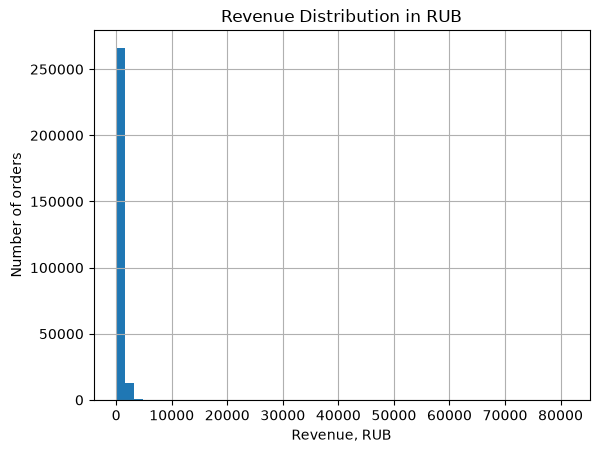

In [29]:
# Create a histogram for rub currency
df[df['currency_code'] == 'rub']['revenue'].hist(bins=50)

plt.title('Revenue Distribution in RUB')
plt.xlabel('Revenue, RUB')
plt.ylabel('Number of orders')
plt.show()

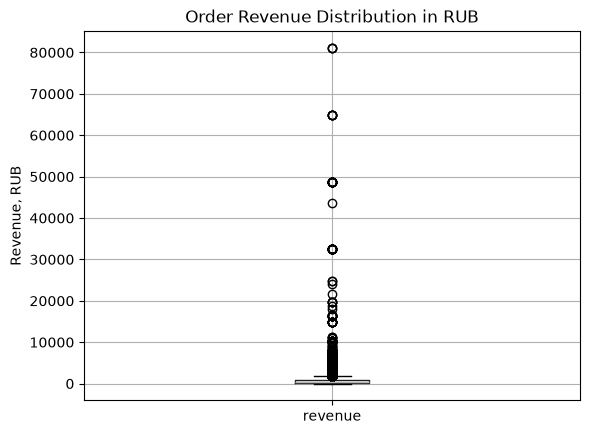

In [30]:
 # Create a boxplot for currency_code = rub
df[df['currency_code'] == 'rub'].boxplot(column='revenue')

plt.title('Order Revenue Distribution in RUB')
plt.ylabel('Revenue, RUB')
plt.show()

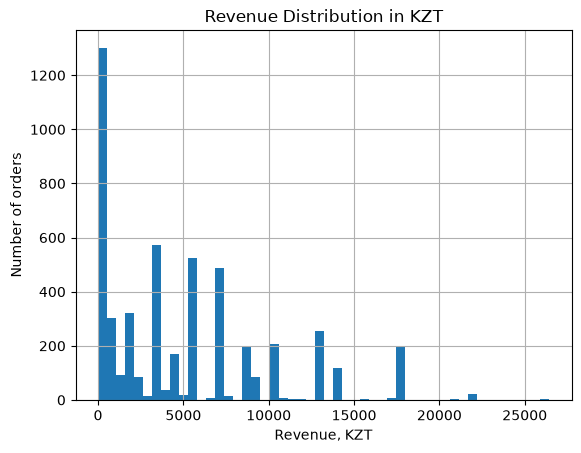

In [31]:
# Create a histogram for kzt currency
df[df['currency_code'] == 'kzt']['revenue'].hist(bins=50)

plt.title('Revenue Distribution in KZT')
plt.xlabel('Revenue, KZT')
plt.ylabel('Number of orders')
plt.show()

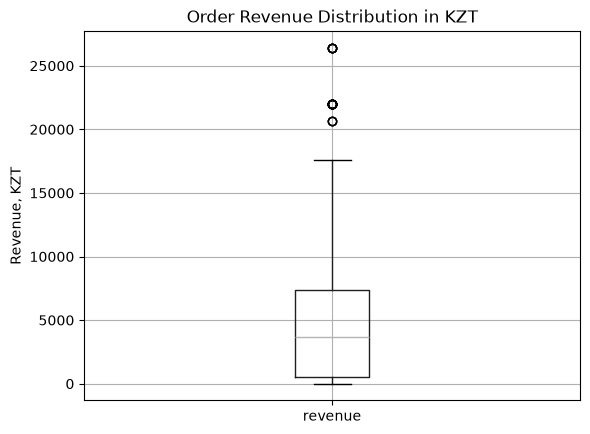

In [32]:
 # Create a boxplot for currency_code = kzt
df[df['currency_code'] == 'kzt'].boxplot(column='revenue')

plt.title('Order Revenue Distribution in KZT')
plt.ylabel('Revenue, KZT')
plt.show()

### Revenue Distribution Analysis

Histograms and boxplots show that `revenue` is strongly right-skewed in both currencies. Most orders have relatively small revenue amounts, while individual orders have substantially higher values.

RUB has a particularly strong right tail: maximum revenue greatly exceeds the values of most orders. KZT also contains extremely high values, but their scale relative to the bulk of the data is smaller.

The data therefore contains extreme upper revenue values that need handling before further analysis. As specified in the assignment, the 99th percentile will be used separately for each currency.

In [33]:
# Examine descriptive statistics for tickets_count
df.groupby('currency_code')['tickets_count'].describe()

,count,mean,std,min,25%,50%,75%,max
currency_code,,,,,,,,
kzt,5063.0,2.763579,1.115602,1.0,2.0,3.0,4.0,6.0
rub,279662.0,2.758144,1.165820,1.0,2.0,3.0,4.0,47.0


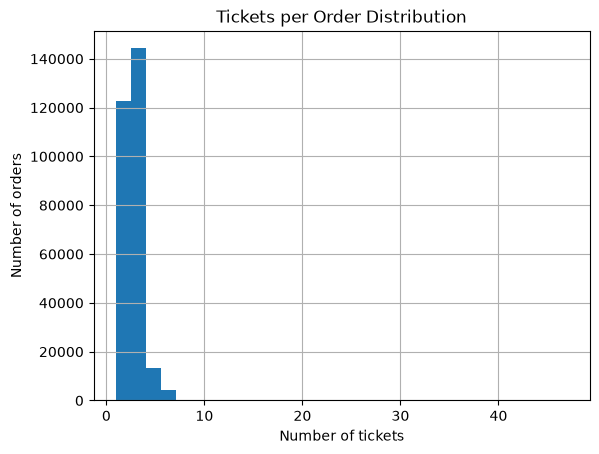

In [34]:
# Create a histogram for tickets_count
df['tickets_count'].hist(bins=30)

plt.title('Tickets per Order Distribution')
plt.xlabel('Number of tickets')
plt.ylabel('Number of orders')
plt.show()

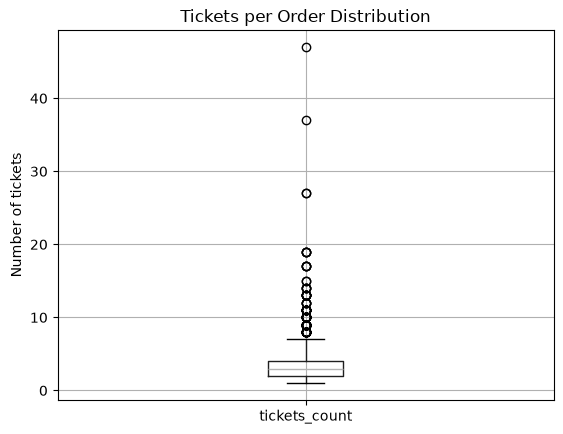

In [35]:
 # Create a boxplot for tickets_count
df.boxplot(column='tickets_count')

plt.title('Tickets per Order Distribution')
plt.ylabel('Number of tickets')
plt.show()

In [36]:
# Examine orders with large ticket counts
df[df['tickets_count'] > 10][
    [
        'order_id',
        'user_id',
        'tickets_count',
        'revenue',
        'total',
        'device_type_canonical',
        'created_ts_msk',
        'event_id'
    ]
].sort_values('tickets_count', ascending=False)

,order_id,user_id,tickets_count,revenue,total,device_type_canonical,created_ts_msk,event_id
39447,5338292,18e9aead0a393e7,47,640.41,32020.47,desktop,2024-09-09 10:03:45,561027
154714,8151843,7eb4fc207ecc10f,37,1147.67,19127.89,desktop,2024-09-17 15:41:39,564789
86350,5190682,3ee7dc2e115847f,27,328.49,10949.60,desktop,2024-10-06 13:08:42,575780
86353,5190653,3ee7dc2e115847f,27,328.49,10949.60,desktop,2024-10-06 13:06:40,575780
153451,806143,7eb4fc207ecc10f,19,1926.71,38534.28,desktop,2024-07-19 17:13:59,516731
190605,3091430,9e4f3ad398e1a2e,19,190.06,9502.85,desktop,2024-10-15 14:33:21,573817
279103,8188499,f6af1139a64d911,19,299.02,5980.49,mobile,2024-09-11 19:28:17,542587
153441,806259,7eb4fc207ecc10f,19,1926.71,38534.28,desktop,2024-07-19 17:06:30,516731
153443,806114,7eb4fc207ecc10f,17,1723.90,34478.04,desktop,2024-07-19 16:51:50,516731
153444,806230,7eb4fc207ecc10f,17,1723.90,34478.04,desktop,2024-07-19 17:21:09,516731


In [37]:
# Count orders and users purchasing more than 10 tickets
large_orders = df[df['tickets_count'] > 10]

print('Number of orders:', large_orders['order_id'].nunique())
print('Order share:', large_orders['order_id'].nunique() / df['order_id'].nunique())
print('Number of users:', large_orders['user_id'].nunique())

Number of orders: 42
Order share: 0.00014751075599262446
Number of users: 30


In [38]:
# Check how many large orders belong to individual users
large_orders.groupby('user_id').agg(
    orders_count=('order_id', 'nunique'),
    tickets_count=('tickets_count', 'sum'),
    max_tickets=('tickets_count', 'max')
).sort_values('orders_count', ascending=False).head(20)

,orders_count,tickets_count,max_tickets
user_id,,,
7eb4fc207ecc10f,6,126,37
0beb8fc0c0a9ce1,4,50,15
3ee7dc2e115847f,2,54,27
c37aeb5b39ffcca,2,23,12
9e4f3ad398e1a2e,2,30,19
18e9aead0a393e7,2,60,47
110125b4a429b43,1,12,12
104b3035f811116,1,14,14
1c2a2133e1df1b4,1,15,15


In [39]:
# Compare large order counts at different thresholds
for threshold in [10, 20]:
    large_orders_count = (df['tickets_count'] > threshold).sum()
    
    print(f'More than {threshold} tickets:')
    print(f'Orders: {large_orders_count}')
    print(f'Share: {large_orders_count / len(df):.3%}')
    print()

More than 10 tickets:
Orders: 42
Share: 0.015%

More than 20 tickets:
Orders: 4
Share: 0.001%



### Tickets per Order Analysis

`tickets_count` is right-skewed: most orders contain few tickets. The median is 3 tickets, and 75% of orders contain no more than 4. After the earlier cleaning, the maximum is 47 tickets.

Orders with more than 10 tickets were examined separately, since large purchases may reflect group behavior and differ from typical individual orders. There are 41 such orders, approximately 0.015% of all orders, made by 29 users. Only 4 orders contain more than 20 tickets (approximately 0.001%).

These large orders have positive total amounts and revenue, so there is no reason to consider them erroneous. Given their very small share, no additional filtering by ticket count will be applied. Statistical testing should account for the possibility that individual users with unusually large or frequent purchases behave differently from most users.

In [40]:
# Calculate the 99th percentile
revenue_99 = df.groupby('currency_code')['revenue'].quantile(0.99)

revenue_99

currency_code
kzt    17617.24
rub     2574.32
Name: revenue, dtype: float64

In [41]:
# Filter by the 99th percentile
rows_before = len(df)
df = df[
    ((df['currency_code'] == 'rub') &
     (df['revenue'] <= revenue_99['rub'])) |
    ((df['currency_code'] == 'kzt') &
     (df['revenue'] <= revenue_99['kzt']))
].copy()

In [42]:
rows_after = len(df)

deleted_rows = rows_before - rows_after
deleted_share = deleted_rows / rows_before * 100

print(f'Rows before filtering: {rows_before}')
print(f'Rows after filtering: {rows_after}')
print(f'Rows removed: {deleted_rows}')
print(f'Data removed: {deleted_share:.2f}%')

Rows before filtering: 284725
Rows after filtering: 281900
Rows removed: 2825
Data removed: 0.99%


### Quantitative Feature Analysis Summary

The distributions of the key quantitative features — `revenue`, `total`, and `tickets_count` — were examined.

There are 381 orders with negative revenue. These orders also have negative `total` values, while ticket counts remain positive. Since the study analyzes successful orders and purchased tickets, records with negative monetary values were excluded.

Zero monetary values were also examined. There are 5,525 zero-revenue orders, of which 5,504 also have a zero `total`. These records were excluded because they do not represent successful paid orders. Another 21 orders have zero revenue but positive total amounts and were retained.

`revenue` is strongly right-skewed and contains extremely high values. Since revenue is reported in two currencies, separate thresholds were calculated for RUB and KZT. The 99th percentile was used for filtering: 2,574.32 for RUB and 17,617.24 for KZT.

Removing values above the 99th percentile reduced the record count from 284,725 to 281,900. A total of 2,825 rows, or 0.99% of the data at this preprocessing stage, were excluded.

`tickets_count` is also right-skewed. The median is 3 tickets, and 75% of orders contain no more than 4. The maximum after cleaning is 47 tickets.

Large orders were examined separately. There are 41 orders with more than 10 tickets (approximately 0.015% of all orders), made by 29 users. Only 4 orders contain more than 20 tickets (approximately 0.001%). These orders have positive prices and revenue, so no evidence of errors was found. No additional ticket-count filtering was applied.

In [43]:
# Check for exact duplicates
df.duplicated().sum()

np.int64(0)

In [44]:
# Select columns for duplicate detection
duplicate_columns = [
    'user_id',
    'created_dt_msk',
    'created_ts_msk',
    'event_id',
    'cinema_circuit',
    'age_limit',
    'currency_code',
    'device_type_canonical',
    'revenue',
    'service_name',
    'tickets_count',
    'total'
]

In [45]:
# Display implicit duplicates
implicit_duplicates = df[
    df.duplicated(
        subset=duplicate_columns,
        keep=False
    )
].sort_values(duplicate_columns)

implicit_duplicates

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
11777,1123983,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,...,69796237-909b-42a7-bfb5-c1b8574c4c76,спектакль,театр,№1482,Светополянский округ,Глиноград,54.0,4443.0,"Центр культурного наследия ""Объединение"" и пар...","бул. Карбышева, д. 50"
11778,1123867,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,...,69796237-909b-42a7-bfb5-c1b8574c4c76,спектакль,театр,№1482,Светополянский округ,Глиноград,54.0,4443.0,"Центр культурного наследия ""Объединение"" и пар...","бул. Карбышева, д. 50"
26894,1930705,0dc525d7bacbb0d,2024-07-31,2024-07-31 13:26:11,393430,нет,18,rub,desktop,1556.05,...,b33d7a0b-a715-47e3-803e-02482884a73e,концерт,концерты,№5048,Каменевский регион,Глиногорск,213.0,2704.0,"Летний фестиваль ""Симфония"" Лтд","бул. Боровой, д. 8/1 стр. 43"
26896,1930763,0dc525d7bacbb0d,2024-07-31,2024-07-31 13:26:11,393430,нет,18,rub,desktop,1556.05,...,b33d7a0b-a715-47e3-803e-02482884a73e,концерт,концерты,№5048,Каменевский регион,Глиногорск,213.0,2704.0,"Летний фестиваль ""Симфония"" Лтд","бул. Боровой, д. 8/1 стр. 43"
53715,1935113,206ea45ec11d478,2024-10-29,2024-10-29 16:46:54,442183,нет,16,rub,mobile,601.69,...,dcf6f06f-8499-41d7-8bc2-a0e3d7afe313,концерт,концерты,№894,Каменевский регион,Глиногорск,213.0,4363.0,"Студия дизайна ""Лестница"" Лимитед","наб. Школьная, д. 9/8 стр. 7/5"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
285612,8547809,fd4d47438ebb946,2024-06-19,2024-06-19 15:40:56,489843,нет,18,rub,desktop,989.57,...,25a26bf3-cb70-4f37-a7f0-c97cc065d414,спектакль,театр,№1858,Каменевский регион,Глиногорск,213.0,4017.0,"Студия анимации ""Точка"" Инкорпорэйтед","алл. Тамбовская, д. 7 к. 827"
285619,8548099,fd4d47438ebb946,2024-06-19,2024-06-19 15:40:56,489843,нет,18,rub,desktop,989.57,...,25a26bf3-cb70-4f37-a7f0-c97cc065d414,спектакль,театр,№1858,Каменевский регион,Глиногорск,213.0,4017.0,"Студия анимации ""Точка"" Инкорпорэйтед","алл. Тамбовская, д. 7 к. 827"
285614,8547983,fd4d47438ebb946,2024-06-19,2024-06-19 15:40:56,489843,нет,18,rub,desktop,1319.43,...,25a26bf3-cb70-4f37-a7f0-c97cc065d414,спектакль,театр,№1858,Каменевский регион,Глиногорск,213.0,4017.0,"Студия анимации ""Точка"" Инкорпорэйтед","алл. Тамбовская, д. 7 к. 827"
285615,8548012,fd4d47438ebb946,2024-06-19,2024-06-19 15:40:56,489843,нет,18,rub,desktop,1319.43,...,25a26bf3-cb70-4f37-a7f0-c97cc065d414,спектакль,театр,№1858,Каменевский регион,Глиногорск,213.0,4017.0,"Студия анимации ""Точка"" Инкорпорэйтед","алл. Тамбовская, д. 7 к. 827"


In [46]:
# Count groups of potential duplicates
implicit_duplicates.groupby(duplicate_columns, dropna=False).ngroups

35

In [47]:
# Remove duplicates
df = df.drop_duplicates(
    subset=duplicate_columns,
    keep='first'
).copy()

In [48]:
# Display the row count
df.shape[0]

281862

### Duplicate Check

No exact full-row duplicates were found.

Implicit duplicate bookings were also checked, excluding `order_id`. The comparison used the main order characteristics: user, creation date and time, event, cinema chain, age restriction, currency, device type, revenue, ticketing operator, ticket count, and total order amount.

A total of 75 rows formed 36 groups of potentially duplicated bookings. Records within each group matched on order characteristics but had different `order_id` values, so they were interpreted as implicit duplicates.

One record per group was retained and the remaining 39 repeated records were removed. The resulting dataset contains 287,923 rows.

In [49]:
# Convert dates and timestamps
df['created_dt_msk'] = pd.to_datetime(df['created_dt_msk'])
df['created_ts_msk'] = pd.to_datetime(df['created_ts_msk'])
currency_df['data'] = pd.to_datetime(currency_df['data'])

# Convert identifiers with missing values
df['city_id'] = df['city_id'].astype('Int64')
df['venue_id'] = df['venue_id'].astype('Int64')

# Downcast integer data
df['age_limit'] = df['age_limit'].astype('int8')
df['tickets_count'] = df['tickets_count'].astype('int8')

### Data Type Conversion

`created_dt_msk` and `created_ts_msk` were converted from strings to datetime values. The `data` column in the exchange rate table was also converted to `datetime` for subsequent date-based joining.

`city_id` and `venue_id` identifiers were converted to the nullable integer type `Int64`.

Numeric downcasting was also assessed. `age_limit` and `tickets_count` have small ranges, so they were converted from `int64` to `int8`.

In [50]:
# Join the exchange rate
df = df.merge(
    currency_df[['data', 'nominal', 'curs']],
    how='left',
    left_on='created_dt_msk',
    right_on='data'
)

In [51]:
# Add revenue_rub
df['revenue_rub'] = np.where(
    df['currency_code'] == 'kzt',
    df['revenue'] * df['curs'] / df['nominal'],
    df['revenue']
)

In [52]:
# Add one_ticket_revenue_rub
df['one_ticket_revenue_rub'] = (
    df['revenue_rub'] / df['tickets_count']
)

In [53]:
# Calculate month
df['month'] = df['created_dt_msk'].dt.to_period('M').dt.to_timestamp()

In [54]:
# Add season
def get_season(month):
    if month in [12, 1, 2]:
        return 'winter'
    elif month in [3, 4, 5]:
        return 'spring'
    elif month in [6, 7, 8]:
        return 'summer'
    elif month in [9, 10, 11]:
        return 'autumn'
    else:
        return np.nan

df['season'] = df['created_dt_msk'].dt.month.apply(get_season)
df['season'].value_counts()

season
autumn    167913
summer    113949
Name: count, dtype: int64

### Preprocessing Summary

The data was prepared for further exploratory analysis:

- Before merging, `event_id` uniqueness in the event table was checked to prevent row multiplication during `merge`.
- Missing `days_since_prev` values were found after merging and cannot be unambiguously reconstructed without additional information. Since this metric is used in statistical analysis, its quality was flagged for further checking.
- There were also 238 orders without event information, approximately 0.08% of the data, which were excluded.
- Key categorical features were examined for possible implicit errors and duplicate categories.
- Descriptive statistics and distributions were examined for `revenue`, `total`, and `tickets_count`.
- Orders with negative monetary values were excluded because the study considers successful purchases.
- Orders with both zero `revenue` and zero `total` were also removed. Orders with zero revenue but positive total prices were retained.
- The 99th percentile was calculated separately for RUB and KZT to handle extremely high `revenue` values. The thresholds were 2,574.32 for RUB and 17,617.24 for KZT. This stage excluded 2,825 rows, or 0.99% of the data.
- Large `tickets_count` orders were examined separately. Orders with more than 10 tickets represent approximately 0.015% of the data and have positive prices and revenue, so no additional ticket-count filtering was applied.
- Exact duplicates and repeated `order_id` values were absent. Repeated records were removed during implicit duplicate booking checks.
- Date and timestamp columns were converted to appropriate types, and some numeric types were downcast.
- Revenue from tenge orders was converted to Russian rubles using the exchange rate on the order date.
- New features were created:
  - `revenue_rub` — order revenue in Russian rubles;
  - `one_ticket_revenue_rub` — ruble revenue per ticket;
  - `month` — order month;
  - `season` — order season.

After all preprocessing stages, **281862 rows out of the original 290,849** remained: **96.91% of the data** was retained and **3.09%** excluded. The data is ready for further exploratory analysis.

## Exploratory Data Analysis

### Order Distributions by Segment and Seasonal Changes

In [55]:
# Calculate monthly order counts
monthly_orders = (
    df.groupby('month')
    .agg(
        orders_count=('order_id', 'nunique')
    )
    .reset_index()
)

monthly_orders

,month,orders_count
0,2024-06-01,32901
1,2024-07-01,37882
2,2024-08-01,43166
3,2024-09-01,68898
4,2024-10-01,99015


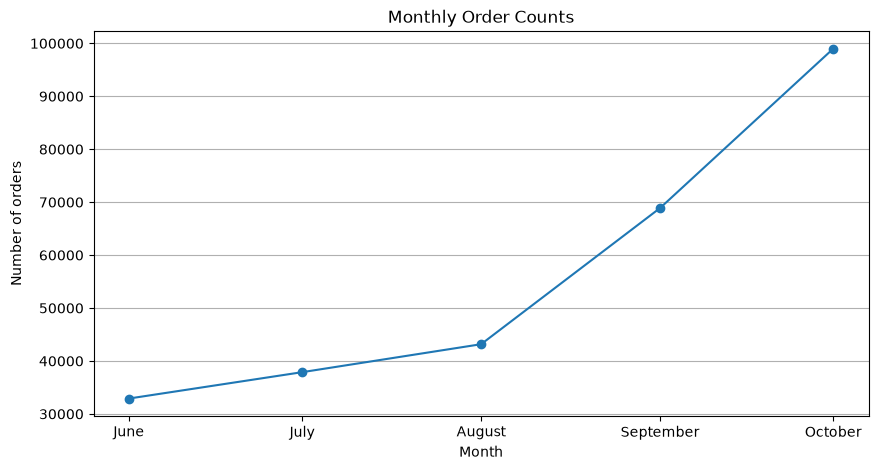

In [56]:
# Create a chart
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_orders['month'],
    monthly_orders['orders_count'],
    marker='o'
)

plt.title('Monthly Order Counts')
plt.xlabel('Month')
plt.ylabel('Number of orders')

plt.xticks(
    monthly_orders['month'],
    ['June', 'July', 'August', 'September', 'October']
)

plt.grid(axis='y')

plt.show()

#### Monthly Order Trends

Order counts increase consistently throughout the period. There were 34,343 orders in June, 40,408 in July, and 44,570 in August. Growth accelerated noticeably in autumn: orders rose to 69,331 in September and 99,271 in October.

The data therefore confirms seasonal changes in user activity: order counts are substantially higher in autumn than in summer. Orders increased almost 2.9-fold from June to October.

In [57]:
# Count the months represented in each season
months_per_season = (
    df.groupby('season')['month']
    .nunique()
)

months_per_season

season
autumn    2
summer    3
Name: month, dtype: int64

In [58]:
# Calculate order counts, shares, and average monthly orders by event type for each season
event_type_season = (
    df.groupby(['season', 'event_type_main'])
    .agg(orders_count=('order_id', 'nunique'))
    .reset_index()
)

event_type_season['share'] = (
    event_type_season['orders_count']
    / event_type_season.groupby('season')['orders_count'].transform('sum')
)

event_type_season['avg_monthly_orders'] = (
    event_type_season['orders_count']
    / event_type_season['season'].map(months_per_season)
)

event_type_season

,season,event_type_main,orders_count,share,avg_monthly_orders
0,autumn,выставки,2402,0.014305,1201.000000
1,autumn,другое,32672,0.194577,16336.000000
2,autumn,концерты,62724,0.373551,31362.000000
3,autumn,спорт,18778,0.111832,9389.000000
4,autumn,стендап,6923,0.041230,3461.500000
5,autumn,театр,42722,0.254429,21361.000000
6,autumn,ёлки,1692,0.010077,846.000000
7,summer,выставки,2407,0.021123,802.333333
8,summer,другое,28477,0.249910,9492.333333
9,summer,концерты,49985,0.438661,16661.666667


In [59]:
# Reshape the table
event_type_pivot = event_type_season.pivot(
    index='event_type_main',
    columns='season',
    values='share'
)

event_type_pivot

season,autumn,summer
event_type_main,,
выставки,0.014305,0.021123
другое,0.194577,0.249910
концерты,0.373551,0.438661
спорт,0.111832,0.024239
стендап,0.041230,0.055692
театр,0.254429,0.207979
ёлки,0.010077,0.002396


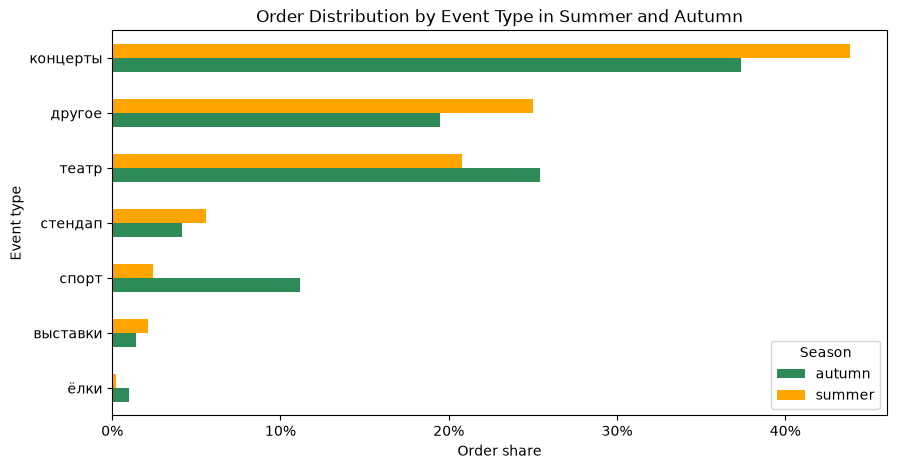

In [60]:
# Sort event types by their summer order shares
event_type_pivot = event_type_pivot.sort_values(
    by='summer',
    ascending=True
)

# Create a horizontal bar chart
event_type_pivot.plot(
    kind='barh',
    figsize=(10, 5),
    color=['seagreen', 'orange']
)

plt.title('Order Distribution by Event Type in Summer and Autumn')
plt.xlabel('Order share')
plt.ylabel('Event type')
plt.legend(title='Season')

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:.0%}')
)

plt.show()

In [61]:
# Reshape the table to compare average monthly orders
event_type_monthly_pivot = event_type_season.pivot(
    index='event_type_main',
    columns='season',
    values='avg_monthly_orders'
)

event_type_monthly_pivot

season,autumn,summer
event_type_main,,
выставки,1201.0,802.333333
другое,16336.0,9492.333333
концерты,31362.0,16661.666667
спорт,9389.0,920.666667
стендап,3461.5,2115.333333
театр,21361.0,7899.666667
ёлки,846.0,91.000000


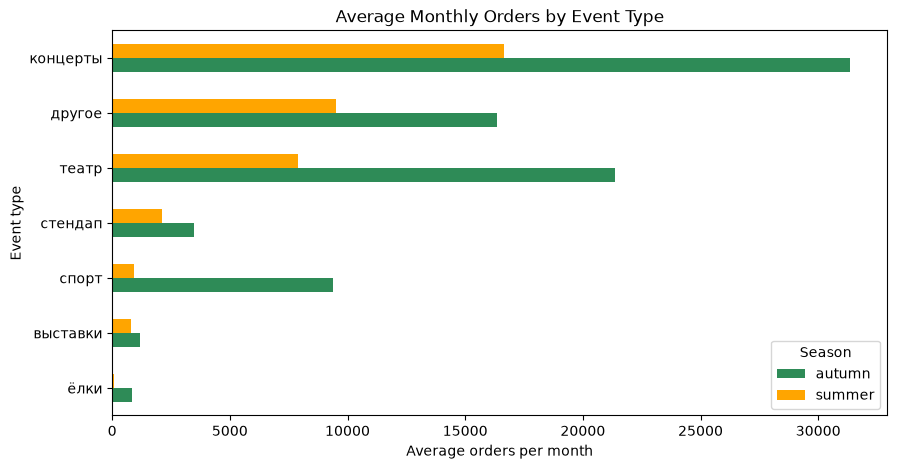

In [62]:
# Sort categories by average monthly orders in summer
event_type_monthly_pivot = event_type_monthly_pivot.sort_values(
    by='summer'
)

# Plot average monthly orders in summer and autumn
event_type_monthly_pivot.plot(
    kind='barh',
    figsize=(10, 5),
    color=['seagreen', 'orange']
)

plt.title('Average Monthly Orders by Event Type')
plt.xlabel('Average orders per month')
plt.ylabel('Event type')
plt.legend(title='Season')

plt.show()

In [63]:
# Calculate order counts, shares, and average monthly orders
# by device type for each season
device_type_season = (
    df.groupby(['season', 'device_type_canonical'])
    .agg(orders_count=('order_id', 'nunique'))
    .reset_index()
)

device_type_season['share'] = (
    device_type_season['orders_count']
    / device_type_season.groupby('season')['orders_count'].transform('sum')
)

device_type_season['avg_monthly_orders'] = (
    device_type_season['orders_count']
    / device_type_season['season'].map(months_per_season)
)

device_type_season

,season,device_type_canonical,orders_count,share,avg_monthly_orders
0,autumn,desktop,34249,0.203969,17124.500000
1,autumn,mobile,133664,0.796031,66832.000000
2,summer,desktop,21779,0.191129,7259.666667
3,summer,mobile,92170,0.808871,30723.333333


In [64]:
device_pivot = device_type_season.pivot(
    index='device_type_canonical',
    columns='season',
    values='share'
)

device_pivot

season,autumn,summer
device_type_canonical,,
desktop,0.203969,0.191129
mobile,0.796031,0.808871


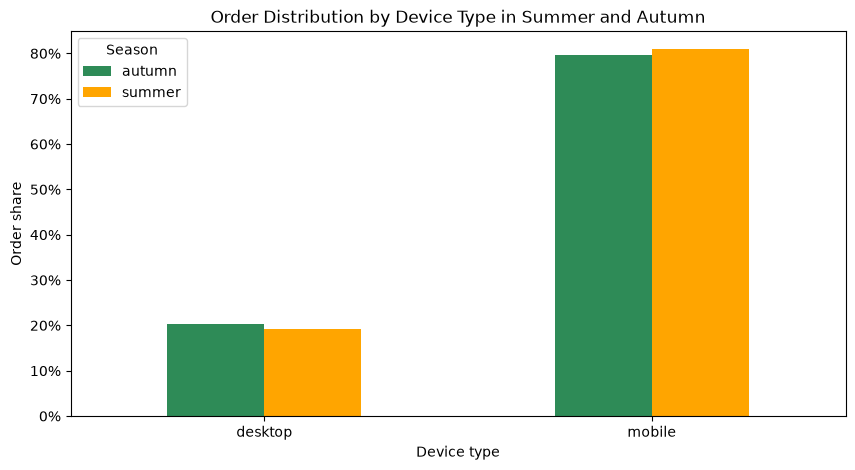

In [65]:
# Create a bar chart
device_pivot.plot(
    kind='bar',
    figsize=(10, 5),
    color=['seagreen', 'orange']
)

plt.title('Order Distribution by Device Type in Summer and Autumn')
plt.xlabel('Device type')
plt.ylabel('Order share')
plt.xticks(rotation=0)
plt.legend(title='Season')

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:.0%}')
)

plt.show()

In [66]:
# Reshape the table to compare average monthly orders
device_type_monthly_pivot = device_type_season.pivot(
    index='device_type_canonical',
    columns='season',
    values='avg_monthly_orders'
)

device_type_monthly_pivot

season,autumn,summer
device_type_canonical,,
desktop,17124.5,7259.666667
mobile,66832.0,30723.333333


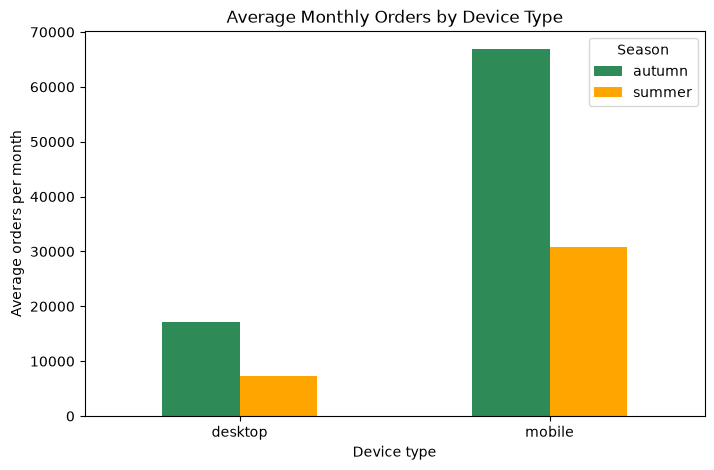

In [67]:
# Plot average monthly orders by device type in summer and autumn
device_type_monthly_pivot.plot(
    kind='bar',
    figsize=(8, 5),
    color=['seagreen', 'orange']
)

plt.title('Average Monthly Orders by Device Type')
plt.xlabel('Device type')
plt.ylabel('Average orders per month')
plt.xticks(rotation=0)
plt.legend(title='Season')

plt.show()

In [68]:
# Calculate order counts and shares by age rating for each season
age_limit_season = (
    df.groupby(['season', 'age_limit'])
    .agg(orders_count=('order_id', 'nunique'))
    .reset_index()
)

age_limit_season['share'] = (
    age_limit_season['orders_count']
    / age_limit_season.groupby('season')['orders_count'].transform('sum')
)

age_limit_season['avg_monthly_orders'] = (
    age_limit_season['orders_count']
    / age_limit_season['season'].map(months_per_season)
)

age_limit_season

,season,age_limit,orders_count,share,avg_monthly_orders
0,autumn,0,39299,0.234044,19649.500000
1,autumn,6,29648,0.176568,14824.000000
2,autumn,12,37225,0.221692,18612.500000
3,autumn,16,44203,0.263249,22101.500000
4,autumn,18,17538,0.104447,8769.000000
5,summer,0,20660,0.181309,6886.666667
6,summer,6,20880,0.183240,6960.000000
7,summer,12,24205,0.212420,8068.333333
8,summer,16,32390,0.284250,10796.666667
9,summer,18,15814,0.138781,5271.333333


In [69]:
# Reshape the table
age_limit_pivot = age_limit_season.pivot(
    index='age_limit',
    columns='season',
    values='share'
)

age_limit_pivot

season,autumn,summer
age_limit,,
0,0.234044,0.181309
6,0.176568,0.183240
12,0.221692,0.212420
16,0.263249,0.284250
18,0.104447,0.138781


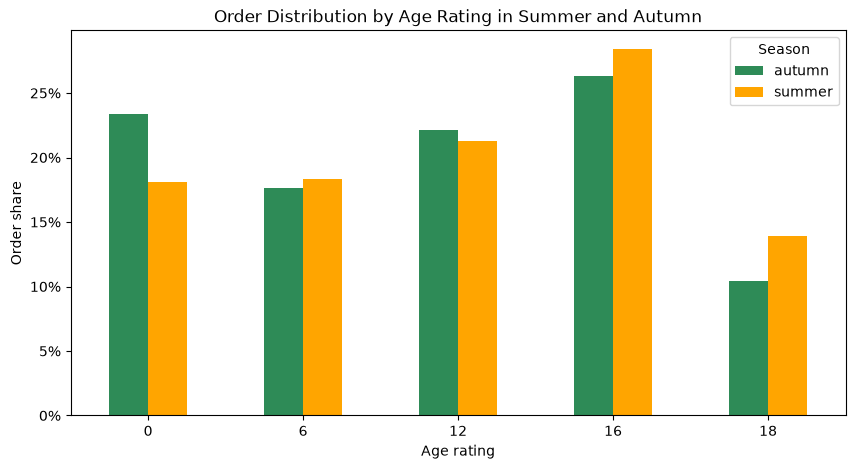

In [70]:
# Create a bar chart
age_limit_pivot.plot(
    kind='bar',
    figsize=(10, 5),
    color=['seagreen', 'orange']
)

plt.title('Order Distribution by Age Rating in Summer and Autumn')
plt.xlabel('Age rating')
plt.ylabel('Order share')
plt.xticks(rotation=0)
plt.legend(title='Season')

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:.0%}')
)

plt.show()

In [71]:
# Reshape the table to compare average monthly orders
age_limit_monthly_pivot = age_limit_season.pivot(
    index='age_limit',
    columns='season',
    values='avg_monthly_orders'
)

age_limit_monthly_pivot

season,autumn,summer
age_limit,,
0,19649.5,6886.666667
6,14824.0,6960.000000
12,18612.5,8068.333333
16,22101.5,10796.666667
18,8769.0,5271.333333


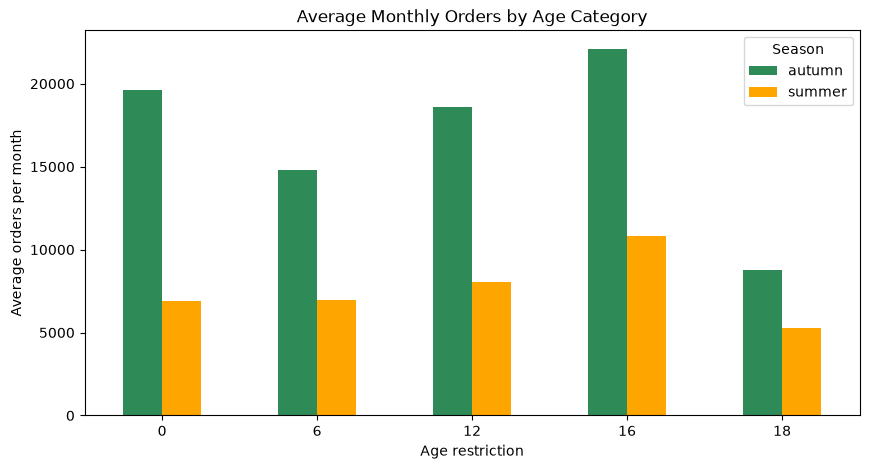

In [72]:
# Plot average monthly orders by age category in summer and autumn
age_limit_monthly_pivot.plot(
    kind='bar',
    figsize=(10, 5),
    color=['seagreen', 'orange']
)

plt.title('Average Monthly Orders by Age Category')
plt.xlabel('Age restriction')
plt.ylabel('Average orders per month')
plt.xticks(rotation=0)
plt.legend(title='Season')

plt.show()

#### Order Distribution Findings by Segment

Average monthly orders increased in all examined segments in autumn. The order mix also changed: some categories grew faster than others, affecting their shares.

Concerts remain the leading event type. Despite their share falling from 43.9% in summer to 37.4% in autumn, average monthly orders rose from 16.7K to 31.4K. Sports demand grew particularly strongly: its share increased from 2.4% to 11.2%, and average monthly orders from 0.9K to 9.4K. Theater also grew substantially: its share rose from 20.8% to 25.4%, and average monthly orders from 7.9K to 21.4K. Thus, a falling share for categories such as concerts does not indicate lower demand: autumn orders increased in every category, but sports and theater grew especially quickly.

The device distribution of orders barely changed. Mobile devices remain the primary ordering channel, accounting for approximately 80% in both seasons. Average monthly mobile orders increased from 30.7K in summer to 66.8K in autumn, while desktop orders rose from 7.3K to 17.1K. Activity therefore increased on both device types without a substantial change in their ratio.

Average monthly orders also increased in all age categories. The 16+ category remains the largest in autumn, with 22.1K orders per month versus 10.8K in summer. The 0+ category grew especially strongly, from 6.9K to 19.6K monthly orders, while also increasing its share. Conversely, the 18+ share fell, but average monthly orders still increased from 5.3K to 8.8K. Declining shares therefore reflect faster growth in other categories rather than fewer orders.

Overall, autumn shows a general rise in user demand: average monthly orders increased across all examined segments. The most noticeable structural changes occurred in event types and age categories, while the mobile/desktop ratio remained nearly stable. Seasonal interpretation should consider both shares and average monthly orders, since summer covers three months and autumn only two.

In [73]:
# Calculate average revenue per ticket by event type for each season
ticket_revenue_season = (
    df.groupby(['season', 'event_type_main'])
    .agg(
        avg_ticket_revenue=('one_ticket_revenue_rub', 'mean')
    )
    .reset_index()
)

ticket_revenue_season

,season,event_type_main,avg_ticket_revenue
0,autumn,выставки,91.905093
1,autumn,другое,77.409532
2,autumn,концерты,268.429855
3,autumn,спорт,50.245481
4,autumn,стендап,231.124973
5,autumn,театр,176.022399
6,autumn,ёлки,229.957055
7,summer,выставки,86.744476
8,summer,другое,88.021277
9,summer,концерты,309.556217


In [74]:
# Reshape the table
ticket_revenue_pivot = ticket_revenue_season.pivot(
    index='event_type_main',
    columns='season',
    values='avg_ticket_revenue'
)

ticket_revenue_pivot

season,autumn,summer
event_type_main,,
выставки,91.905093,86.744476
другое,77.409532,88.021277
концерты,268.429855,309.556217
спорт,50.245481,55.247119
стендап,231.124973,218.518107
театр,176.022399,216.343584
ёлки,229.957055,271.436176


In [75]:
# Calculate the relative change in average ticket revenue in autumn compared with summer
ticket_revenue_pivot['change_pct'] = (
    (ticket_revenue_pivot['autumn'] - ticket_revenue_pivot['summer'])
    / ticket_revenue_pivot['summer']
    * 100
)

ticket_revenue_pivot

season,autumn,summer,change_pct
event_type_main,,,
выставки,91.905093,86.744476,5.949217
другое,77.409532,88.021277,-12.055887
концерты,268.429855,309.556217,-13.285587
спорт,50.245481,55.247119,-9.053210
стендап,231.124973,218.518107,5.769255
театр,176.022399,216.343584,-18.637569
ёлки,229.957055,271.436176,-15.281353


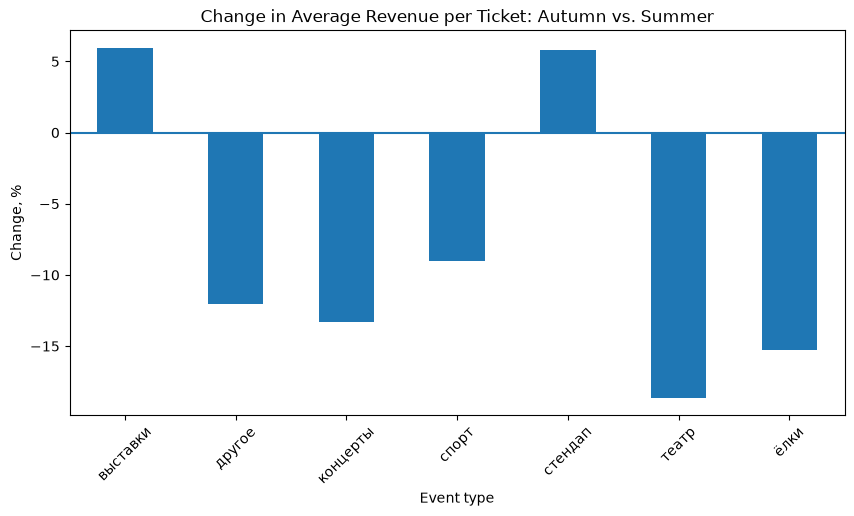

In [76]:
# Visualize
ticket_revenue_pivot['change_pct'].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Change in Average Revenue per Ticket: Autumn vs. Summer')
plt.xlabel('Event type')
plt.ylabel('Change, %')
plt.xticks(rotation=45)
plt.axhline(0)
plt.show()

#### Changes in Average Revenue per Ticket

Average revenue per ticket changed differently across event types in autumn.

The largest decline occurred in theater events — 17.8% compared with summer. Average revenue per ticket for New Year shows fell by 15.4%, and for concerts by 12.0%. Changes in sports and the 'other' category were small: declines of 1.6% and 1.7%, respectively.

Average revenue per ticket increased only for exhibitions and stand-up comedy — by 4.8% and 5.8%, respectively.

Thus, despite substantial autumn growth in total orders, most event types did not see increased average revenue per ticket. Instead, the mean fell noticeably for theater, concerts, and New Year shows.

### Autumn User Activity

In [77]:
# Calculate daily autumn orders, DAU, and average ticket price
daily_activity = (
    df[df['season'] == 'autumn'].groupby('created_dt_msk')
    .agg(
        orders_count=('order_id', 'nunique'),
        dau=('user_id', 'nunique'),
        avg_ticket_revenue=('one_ticket_revenue_rub', 'mean')
    )
    .reset_index()
)

# Calculate average orders per active user
daily_activity['orders_per_user'] = (
    daily_activity['orders_count'] /
    daily_activity['dau']
)

daily_activity.head()

,created_dt_msk,orders_count,dau,avg_ticket_revenue,orders_per_user
0,2024-09-01,1314,555,202.149068,2.367568
1,2024-09-02,1370,571,190.847822,2.399299
2,2024-09-03,5090,776,80.713513,6.559278
3,2024-09-04,1758,684,179.567815,2.570175
4,2024-09-05,1940,738,189.902316,2.628726


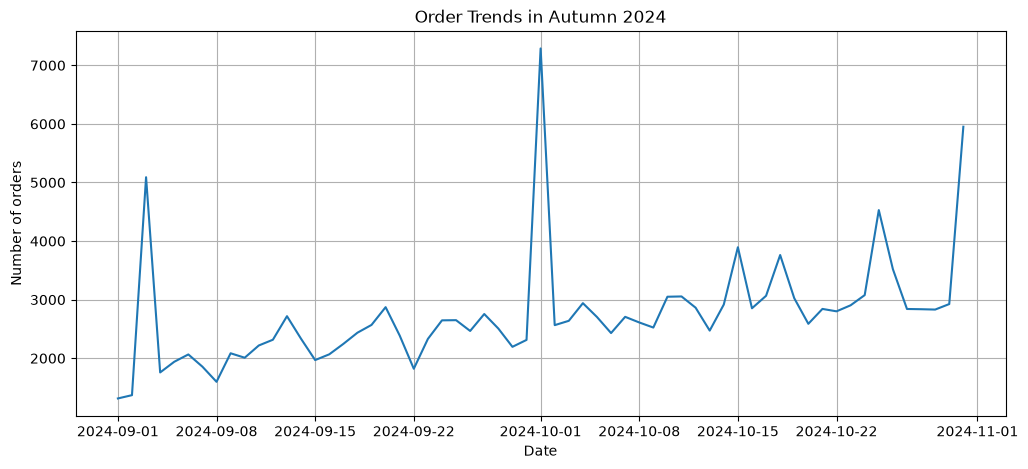

In [78]:
# Plot daily order trends
plt.figure(figsize=(12, 5))

plt.plot(
    daily_activity['created_dt_msk'],
    daily_activity['orders_count']
)

plt.title('Order Trends in Autumn 2024')
plt.xlabel('Date')
plt.ylabel('Number of orders')
plt.grid()
plt.show()

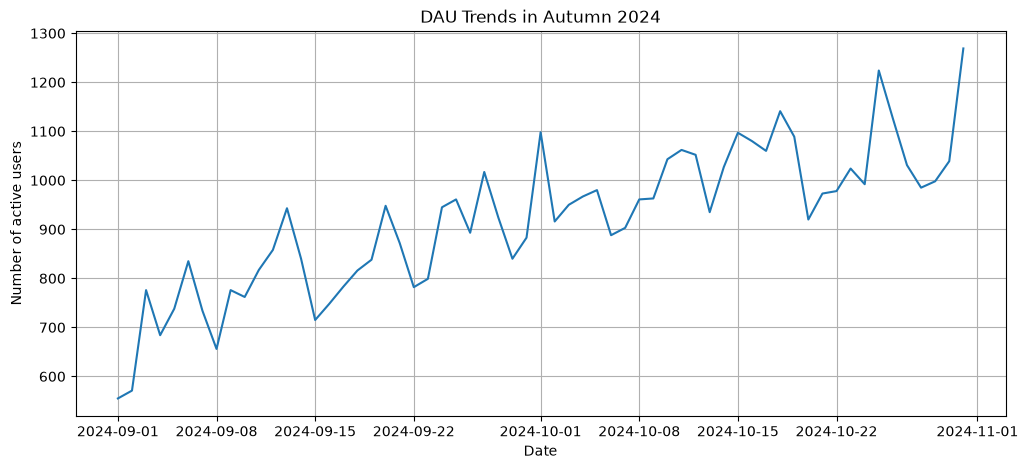

In [79]:
# Plot daily active user trends
plt.figure(figsize=(12, 5))

plt.plot(
    daily_activity['created_dt_msk'],
    daily_activity['dau']
)

plt.title('DAU Trends in Autumn 2024')
plt.xlabel('Date')
plt.ylabel('Number of active users')
plt.grid()
plt.show()

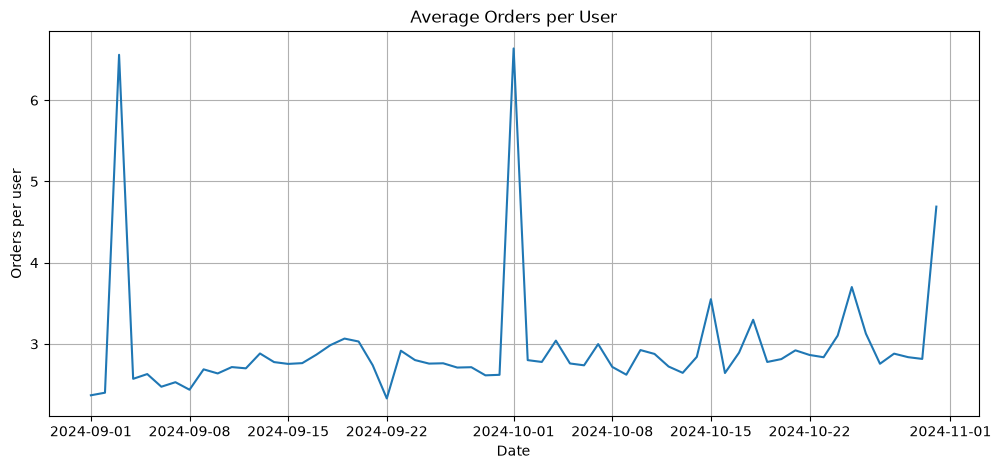

In [80]:
# Plot average orders per user by day
plt.figure(figsize=(12, 5))

plt.plot(
    daily_activity['created_dt_msk'],
    daily_activity['orders_per_user']
)

plt.title('Average Orders per User')
plt.xlabel('Date')
plt.ylabel('Orders per user')
plt.grid()
plt.show()

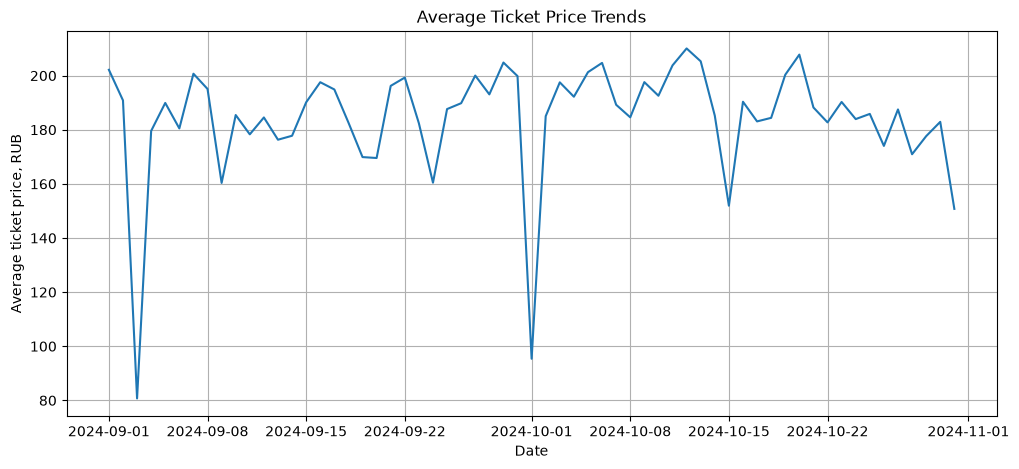

In [81]:
# Plot average ticket price trends by day
plt.figure(figsize=(12, 5))

plt.plot(
    daily_activity['created_dt_msk'],
    daily_activity['avg_ticket_revenue']
)

plt.title('Average Ticket Price Trends')
plt.xlabel('Date')
plt.ylabel('Average ticket price, RUB')
plt.grid()
plt.show()

In [82]:
# Create weekday names
weekday_names = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

# Add the weekday to the daily metrics table
daily_activity['weekday'] = daily_activity['created_dt_msk'].dt.weekday

daily_activity['weekday_name'] = daily_activity['weekday'].map(weekday_names)

In [83]:
# Calculate average user activity for each weekday
weekday_activity = (
    daily_activity.groupby(['weekday', 'weekday_name'])
    .agg(
        avg_orders=('orders_count', 'mean'),
        avg_dau=('dau', 'mean'),
        avg_orders_per_user=('orders_per_user', 'mean')
    )
    .reset_index()
    .sort_values('weekday')
)

weekday_activity

,weekday,weekday_name,avg_orders,avg_dau,avg_orders_per_user
0,0,Monday,2385.333333,851.666667,2.780479
1,1,Tuesday,3490.777778,933.111111,3.718862
2,2,Wednesday,2537.000000,922.222222,2.749092
3,3,Thursday,3008.444444,960.111111,3.060319
4,4,Friday,3087.000000,1017.125000,3.001010
5,5,Saturday,2649.375000,952.125000,2.767604
6,6,Sunday,2136.444444,813.555556,2.605343


In [84]:
# Separate weekdays and weekends
daily_activity['day_type'] = 'weekdays'

daily_activity.loc[
    daily_activity['weekday'].isin([5, 6]),
    'day_type'
] = 'weekends'

# Calculate average weekday and weekend activity
day_type_activity = (
    daily_activity.groupby('day_type')
    .agg(
        avg_orders=('orders_count', 'mean'),
        avg_dau=('dau', 'mean'),
        avg_orders_per_user=('orders_per_user', 'mean')
    )
    .reset_index()
)

day_type_activity

,day_type,avg_orders,avg_dau,avg_orders_per_user
0,weekdays,2897.500000,935.022727,3.063337
1,weekends,2377.823529,878.764706,2.681701


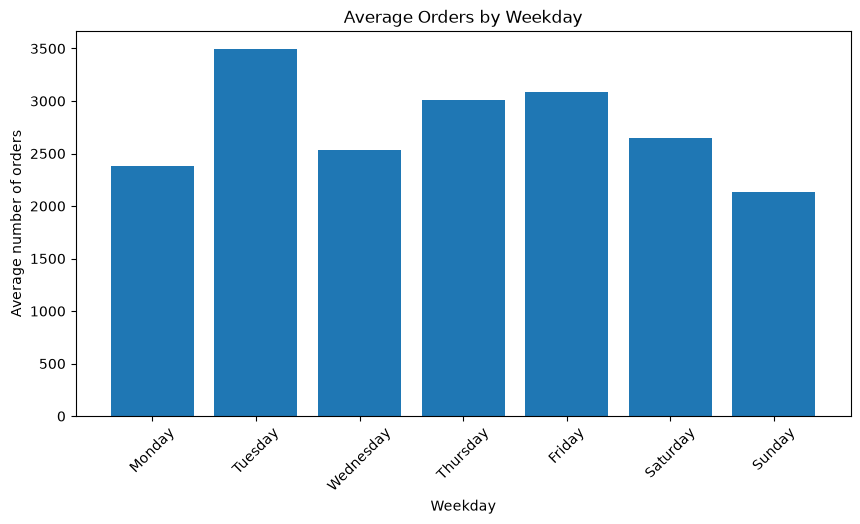

In [85]:
# Plot average orders for each weekday
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_activity['weekday_name'],
    weekday_activity['avg_orders']
)

plt.title('Average Orders by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Average number of orders')
plt.xticks(rotation=45)
plt.show()

#### User Activity and Weekly Patterns
Average user activity is higher on weekdays than weekends. Approximately 2.9K orders are placed on a weekday versus 2.4K on a weekend day. Average active user counts are also higher on weekdays — 937 versus 888.

An active user also places an average of 3.07 orders on weekdays versus 2.68 on weekends. Higher weekday order counts therefore reflect both more active users and greater order intensity per user.

Tuesday has the highest average order count among individual weekdays. However, isolated anomalous activity spikes visible in the daily trend chart may affect this metric, so interpreting Tuesday as consistently the most active day requires caution.

### Popular Events and Partners

In [86]:
# Calculate unique event and order counts for each region
region_stats = (
    df.groupby('region_name')
    .agg(
        events_count=('event_id', 'nunique'),
        orders_count=('order_id', 'nunique')
    )
    .reset_index()
)

region_stats

,region_name,events_count,orders_count
0,Белоярская область,57,199
1,Берестовский округ,39,393
2,Берёзовская область,134,1147
3,Боровлянский край,97,1721
4,Верховинская область,7,45
...,...,...,...
76,Шанырский регион,26,2604
77,Широковская область,1217,16087
78,Яблоневская область,534,6120
79,Ягодиновская область,118,1030


In [87]:
# Calculate each region's event and order shares
region_stats['events_share'] = (
    region_stats['events_count']
    / region_stats['events_count'].sum()
)

region_stats['orders_share'] = (
    region_stats['orders_count']
    / region_stats['orders_count'].sum()
)

In [88]:
# Select the 10 regions with the most unique events
top_regions_events = (
    region_stats
    .sort_values('events_count', ascending=False)
    .head(10)
)

top_regions_events

,region_name,events_count,orders_count,events_share,orders_share
23,Каменевский регион,5794,85400,0.263184,0.302985
60,Североярская область,3777,43590,0.171565,0.154650
77,Широковская область,1217,16087,0.055280,0.057074
57,Светополянский округ,1065,7482,0.048376,0.026545
52,Речиновская область,701,6265,0.031842,0.022227
74,Травяная область,667,4719,0.030298,0.016742
11,Горицветская область,551,5152,0.025028,0.018278
61,Серебринская область,541,5586,0.024574,0.019818
78,Яблоневская область,534,6120,0.024256,0.021713
69,Тепляковская область,528,4383,0.023984,0.015550


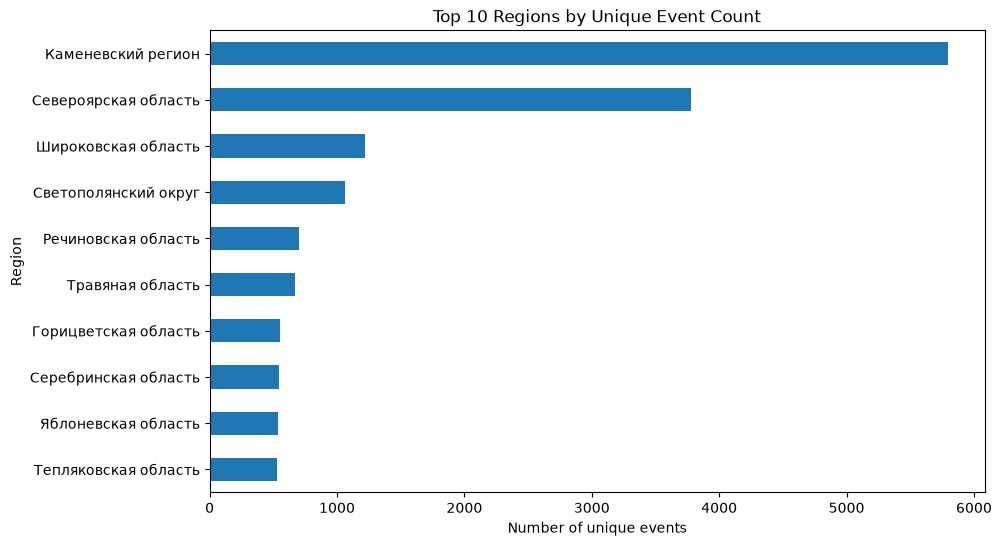

In [89]:
# Create a horizontal bar chart
top_regions_events.sort_values('events_count').plot(
    x='region_name',
    y='events_count',
    kind='barh',
    figsize=(10, 6),
    legend=False
)

plt.title('Top 10 Regions by Unique Event Count')
plt.xlabel('Number of unique events')
plt.ylabel('Region')
plt.show()

In [90]:
# Select the 10 regions with the most orders
top_regions_orders = (
    region_stats
    .sort_values('orders_count', ascending=False)
    .head(10)
)

top_regions_orders

,region_name,events_count,orders_count,events_share,orders_share
23,Каменевский регион,5794,85400,0.263184,0.302985
60,Североярская область,3777,43590,0.171565,0.154650
77,Широковская область,1217,16087,0.055280,0.057074
42,Медовская область,462,13585,0.020986,0.048197
45,Озернинский край,349,10405,0.015853,0.036915
57,Светополянский округ,1065,7482,0.048376,0.026545
41,Малиновоярский округ,165,6314,0.007495,0.022401
52,Речиновская область,701,6265,0.031842,0.022227
64,Солнечноземская область,520,6234,0.023620,0.022117
78,Яблоневская область,534,6120,0.024256,0.021713


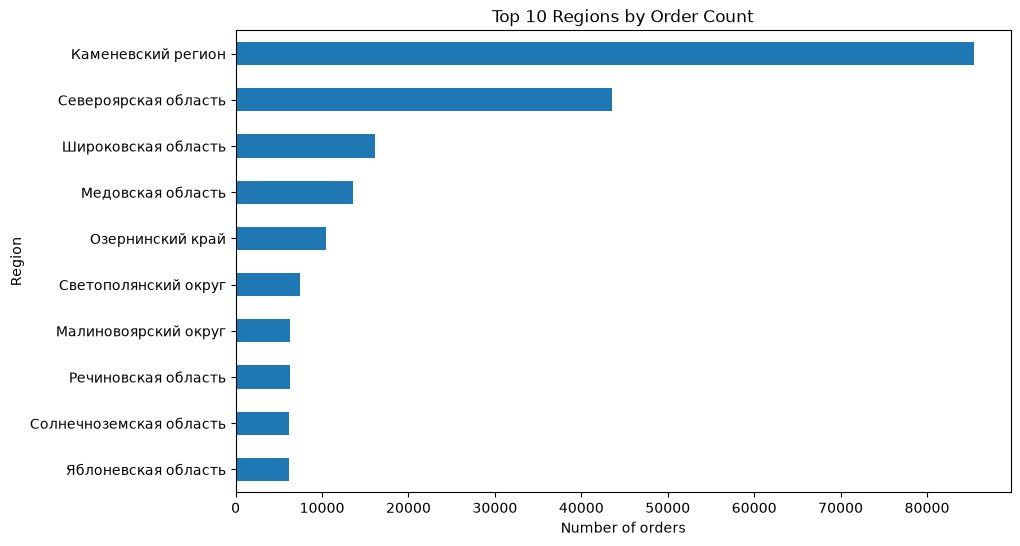

In [91]:
# Create a horizontal bar chart
top_regions_orders.sort_values('orders_count').plot(
    x='region_name',
    y='orders_count',
    kind='barh',
    figsize=(10, 6),
    legend=False
)

plt.title('Top 10 Regions by Order Count')
plt.xlabel('Number of orders')
plt.ylabel('Region')
plt.show()

In [92]:
# Calculate unique events, orders, and total revenue for each ticketing partner
partner_stats = (
    df.groupby('service_name')
    .agg(
        events_count=('event_id', 'nunique'),
        orders_count=('order_id', 'nunique'),
        revenue_sum=('revenue_rub', 'sum')
    )
    .reset_index()
)

partner_stats

,service_name,events_count,orders_count,revenue_sum
0,Crazy ticket!,256,789,4.519248e+05
1,Show_ticket,295,2090,1.449276e+06
2,Билет по телефону,20,85,7.244740e+04
3,Билеты без проблем,4020,57863,2.432505e+07
4,Билеты в интернете,1,4,5.482300e+02
5,Билеты в руки,3486,39801,1.319416e+07
6,Быстробилет,255,1982,1.532847e+06
7,Быстрый кассир,20,379,3.966899e+05
8,Весь в билетах,856,16426,1.653750e+07
9,Восьмёрка,143,1106,6.578092e+05


In [93]:
# Check whether orders for one event can be processed by different ticketing partners
df.groupby('event_id')['service_name'].nunique().value_counts().sort_index()

service_name
1     20807
2       805
3       199
4        94
5        55
6        26
7        17
8         8
9         3
10        1
Name: count, dtype: int64

Therefore, the same event can indeed appear with multiple ticketing partners.

In [94]:
# Calculate the share of all unique events handled by each partner
partner_stats['events_share'] = (
    partner_stats['events_count']
    / df['event_id'].nunique()
)

# Calculate the share of orders processed by each partner
partner_stats['orders_share'] = (
    partner_stats['orders_count']
    / partner_stats['orders_count'].sum()
)

# Calculate each partner's share of total revenue
partner_stats['revenue_share'] = (
    partner_stats['revenue_sum']
    / partner_stats['revenue_sum'].sum()
)

partner_stats

,service_name,events_count,orders_count,revenue_sum,events_share,orders_share,revenue_share
0,Crazy ticket!,256,789,4.519248e+05,0.011628,0.002799,3.027629e-03
1,Show_ticket,295,2090,1.449276e+06,0.013400,0.007415,9.709296e-03
2,Билет по телефону,20,85,7.244740e+04,0.000908,0.000302,4.853548e-04
3,Билеты без проблем,4020,57863,2.432505e+07,0.182603,0.205288,1.629635e-01
4,Билеты в интернете,1,4,5.482300e+02,0.000045,0.000014,3.672817e-06
5,Билеты в руки,3486,39801,1.319416e+07,0.158347,0.141207,8.839307e-02
6,Быстробилет,255,1982,1.532847e+06,0.011583,0.007032,1.026917e-02
7,Быстрый кассир,20,379,3.966899e+05,0.000908,0.001345,2.657588e-03
8,Весь в билетах,856,16426,1.653750e+07,0.038883,0.058277,1.107915e-01
9,Восьмёрка,143,1106,6.578092e+05,0.006496,0.003924,4.406933e-03


In [95]:
# Select and sort the top 10 partners by unique event count
top_partners_events = (
    partner_stats
    .sort_values('events_count', ascending=False)
    .head(10)
)

top_partners_events

,service_name,events_count,orders_count,revenue_sum,events_share,orders_share,revenue_share
21,Лови билет!,4819,40523,1.667647e+07,0.218896,0.143769,0.111722
3,Билеты без проблем,4020,57863,2.432505e+07,0.182603,0.205288,0.162963
5,Билеты в руки,3486,39801,1.319416e+07,0.158347,0.141207,0.088393
25,Облачко,2335,26402,1.858861e+07,0.106064,0.093670,0.124533
22,Лучшие билеты,1741,17619,2.724084e+06,0.079082,0.062509,0.018250
24,Мой билет,1296,34427,2.204203e+07,0.058869,0.122141,0.147669
30,Тебе билет!,1061,5189,2.962309e+06,0.048194,0.018410,0.019846
26,Прачечная,1026,10222,4.746811e+06,0.046605,0.036266,0.031801
8,Весь в билетах,856,16426,1.653750e+07,0.038883,0.058277,0.110791
35,Яблоко,714,5004,3.868337e+06,0.032432,0.017753,0.025916


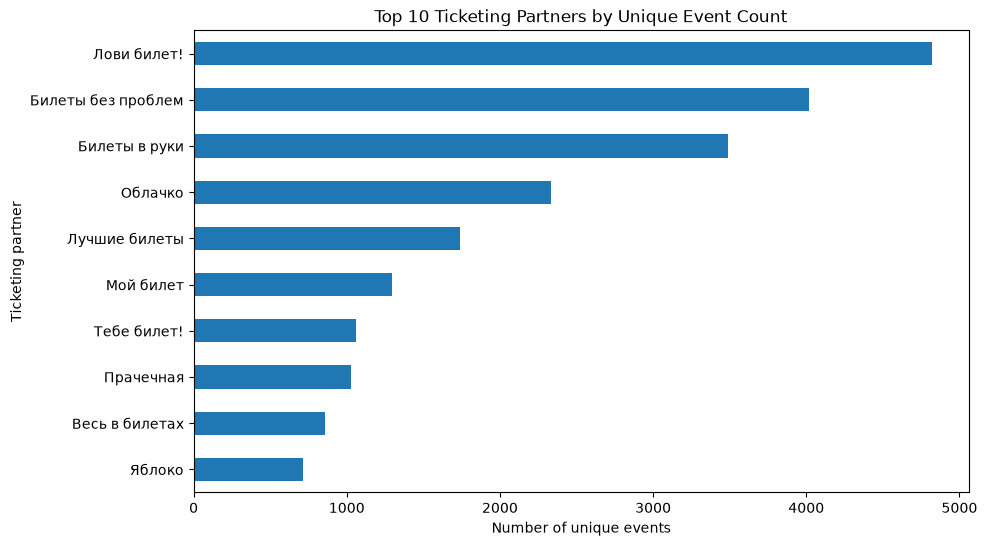

In [96]:
# Plot the top 10 partners by unique event count
top_partners_events.sort_values('events_count').plot(
    x='service_name',
    y='events_count',
    kind='barh',
    figsize=(10, 6),
    legend=False
)

plt.title('Top 10 Ticketing Partners by Unique Event Count')
plt.xlabel('Number of unique events')
plt.ylabel('Ticketing partner')
plt.show()

In [97]:
# Select and sort the top 10 partners by processed order count
top_partners_orders = (
    partner_stats
    .sort_values('orders_count', ascending=False)
    .head(10)
)

top_partners_orders

,service_name,events_count,orders_count,revenue_sum,events_share,orders_share,revenue_share
3,Билеты без проблем,4020,57863,2.432505e+07,0.182603,0.205288,0.162963
21,Лови билет!,4819,40523,1.667647e+07,0.218896,0.143769,0.111722
5,Билеты в руки,3486,39801,1.319416e+07,0.158347,0.141207,0.088393
24,Мой билет,1296,34427,2.204203e+07,0.058869,0.122141,0.147669
25,Облачко,2335,26402,1.858861e+07,0.106064,0.093670,0.124533
22,Лучшие билеты,1741,17619,2.724084e+06,0.079082,0.062509,0.018250
8,Весь в билетах,856,16426,1.653750e+07,0.038883,0.058277,0.110791
26,Прачечная,1026,10222,4.746811e+06,0.046605,0.036266,0.031801
19,Край билетов,252,6109,6.405689e+06,0.011447,0.021674,0.042914
30,Тебе билет!,1061,5189,2.962309e+06,0.048194,0.018410,0.019846


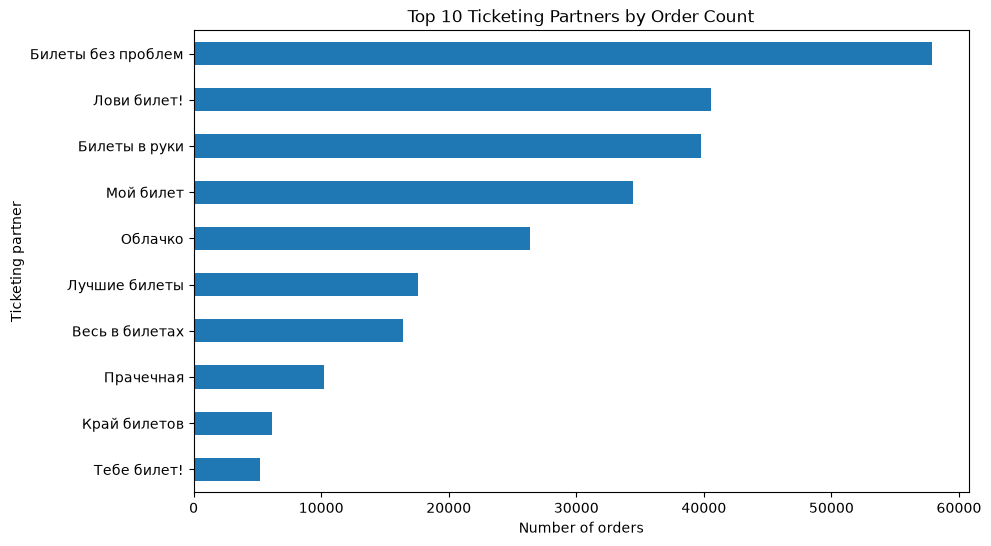

In [98]:
# Plot the top 10 partners by processed order count
top_partners_orders.sort_values('orders_count').plot(
    x='service_name',
    y='orders_count',
    kind='barh',
    figsize=(10, 6),
    legend=False
)

plt.title('Top 10 Ticketing Partners by Order Count')
plt.xlabel('Number of orders')
plt.ylabel('Ticketing partner')
plt.show()

In [99]:
# Select and sort the top 10 partners by total revenue
top_partners_revenue = (
    partner_stats
    .sort_values('revenue_sum', ascending=False)
    .head(10)
)

top_partners_revenue

,service_name,events_count,orders_count,revenue_sum,events_share,orders_share,revenue_share
3,Билеты без проблем,4020,57863,2.432505e+07,0.182603,0.205288,0.162963
24,Мой билет,1296,34427,2.204203e+07,0.058869,0.122141,0.147669
25,Облачко,2335,26402,1.858861e+07,0.106064,0.093670,0.124533
21,Лови билет!,4819,40523,1.667647e+07,0.218896,0.143769,0.111722
8,Весь в билетах,856,16426,1.653750e+07,0.038883,0.058277,0.110791
5,Билеты в руки,3486,39801,1.319416e+07,0.158347,0.141207,0.088393
19,Край билетов,252,6109,6.405689e+06,0.011447,0.021674,0.042914
26,Прачечная,1026,10222,4.746811e+06,0.046605,0.036266,0.031801
13,Дом культуры,272,4412,4.358656e+06,0.012355,0.015653,0.029200
35,Яблоко,714,5004,3.868337e+06,0.032432,0.017753,0.025916


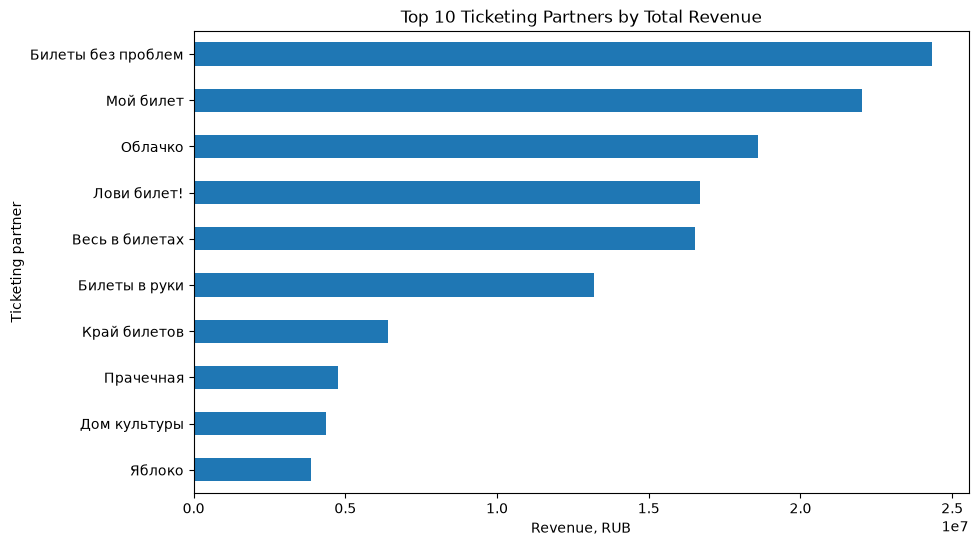

In [100]:
# Plot the top 10 partners by total revenue
top_partners_revenue.sort_values('revenue_sum').plot(
    x='service_name',
    y='revenue_sum',
    kind='barh',
    figsize=(10, 6),
    legend=False
)

plt.title('Top 10 Ticketing Partners by Total Revenue')
plt.xlabel('Revenue, RUB')
plt.ylabel('Ticketing partner')
plt.show()

In [101]:
# Calculate the combined order and revenue shares of the five largest partners
top5_orders_share = (
    partner_stats
    .nlargest(5, 'orders_count')['orders_share']
    .sum()
)

top5_revenue_share = (
    partner_stats
    .nlargest(5, 'revenue_sum')['revenue_share']
    .sum()
)

print(f'Order share of the top 5 partners: {top5_orders_share:.1%}')
print(f'Revenue share of the top 5 partners: {top5_revenue_share:.1%}')

Order share of the top 5 partners: 70.6%
Revenue share of the top 5 partners: 65.8%


#### Interim Findings

The regional distribution of events and orders shows a noticeable concentration of activity in a few regions.

Kamenevsky Region has the greatest event variety, accounting for approximately 26.5% of unique events. It also leads in orders, with around 31.2% of all orders. Severoyarskaya Oblast ranks second, with approximately 17.0% of events and 15.2% of orders. These two regions therefore stand out clearly.

However, event variety is not always directly related to order counts. For example, Svetopolyansky District ranks highly in unique events but has a noticeably smaller order share. Meanwhile, Medovskaya Oblast and Ozerninsky Krai are among the order leaders despite relatively small event shares.

Activity is also unevenly distributed across ticketing partners. 'Lovi bilet!' leads in event coverage, handling approximately 21.8% of all unique events. 'Bilety bez problem' leads in processed orders, with approximately 21.9%.

The order leader 'Bilety bez problem' also leads in revenue, with a share of approximately 16.3%. Partner rankings by orders and revenue do not match entirely. For example, 'Ves v biletakh' processes around 5.7% of orders but generates approximately 11.1% of revenue, while 'Luchshie bilety' accounts for 6.2% of orders and only around 1.8% of revenue. This indicates differences in average order prices across partners.

Overall, orders and revenue are highly concentrated among partners: the five largest account for 71.2% of all orders and 65.8% of revenue. There are therefore clear leaders among regions and ticketing partners, but leadership in event variety, order counts, and revenue does not always coincide.

## Statistical Data Analysis

At this stage, we will test whether activity differs between mobile and desktop users.

Two hypotheses will be tested:

1. The mean number of orders per mobile app user is higher than for desktop users.
2. The mean time between orders for mobile app users is higher than for desktop users.

Only data for autumn 2024 is used in the statistical analysis.

### Comparing Orders per User

We will test whether the mean number of orders per user differs by device type.

First, we will prepare the data. For each user, we will calculate autumn order counts by device type.

In [102]:
# Select only autumn data
autumn_df = df[df['season'] == 'autumn'].copy()

In [103]:
# Calculate each user's order count by device type
user_orders = (
    autumn_df
    .groupby(['user_id', 'device_type_canonical'])
    .agg(orders_count=('order_id', 'nunique'))
    .reset_index()
)

user_orders.head()

,user_id,device_type_canonical,orders_count
0,0005ca5e93f2cf4,mobile,1
1,000898990054619,mobile,2
2,000a55a418c128c,mobile,2
3,001e7037d013f0f,mobile,2
4,00245c702bc343e,mobile,2


In [104]:
# Check how many device types each user used
devices_per_user = (
    autumn_df
    .groupby('user_id')['device_type_canonical']
    .nunique()
)

devices_per_user.value_counts()

device_type_canonical
1    12502
2     3236
Name: count, dtype: int64

To select an appropriate statistical test, examine the distribution of orders per user for mobile and desktop devices.

In [105]:
# Calculate descriptive statistics for orders per user by device type
user_orders.groupby('device_type_canonical')['orders_count'].describe()

,count,mean,std,min,25%,50%,75%,max
device_type_canonical,,,,,,,,
desktop,4862.0,7.044220,35.910972,1.0,1.0,2.0,4.0,1494.0
mobile,14112.0,9.471655,67.957702,1.0,1.0,2.0,5.0,4314.0


Descriptive statistics show higher mean orders per user on mobile: 9.46 versus 7.05 on desktop. Both groups have a median of 2 orders, while maxima greatly exceed the medians. This may indicate outliers and strong right skewness. We will visualize the distributions to inform the test selection.

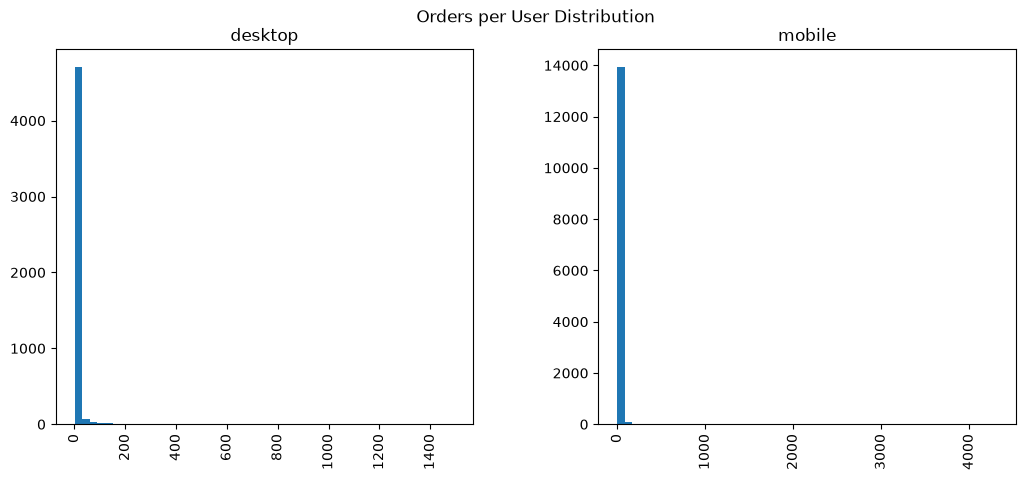

In [106]:
# Plot the distribution of orders per user by device type
user_orders.hist(
    column='orders_count',
    by='device_type_canonical',
    bins=50,
    figsize=(12, 5)
)

plt.suptitle('Orders per User Distribution')
plt.show()

In [107]:
# Calculate the share of users who used both device types
both_devices_share = (
    (devices_per_user == 2).sum()
    / devices_per_user.shape[0]
)

print(f'Share of users with both device types: {both_devices_share:.1%}')

Share of users with both device types: 20.6%


In [108]:
# Select users who used only one device type in autumn
single_device_users = devices_per_user[devices_per_user == 1].index

single_device_df = autumn_df[
    autumn_df['user_id'].isin(single_device_users)
]

# Count unique users by device type
single_device_df.groupby('device_type_canonical')['user_id'].nunique()

device_type_canonical
desktop     1626
mobile     10876
Name: user_id, dtype: int64

In [109]:
# Calculate order counts for users who used only one device type
single_user_orders = (
    single_device_df
    .groupby(['user_id', 'device_type_canonical'])
    .agg(orders_count=('order_id', 'nunique'))
    .reset_index()
)

single_user_orders

,user_id,device_type_canonical,orders_count
0,0005ca5e93f2cf4,mobile,1
1,000898990054619,mobile,2
2,000a55a418c128c,mobile,2
3,001e7037d013f0f,mobile,2
4,00245c702bc343e,mobile,2
...,...,...,...
12497,ffed3ff067d4f12,mobile,3
12498,fff13b79bd47d7c,mobile,3
12499,fff32fc9ad0f9f6,desktop,1
12500,fffeeb3c120cf0b,desktop,1


The statistical comparison selects users who placed orders on only one device type during autumn. Users of both mobile and desktop devices were excluded to ensure independent samples.

Examine descriptive statistics for orders per user in the resulting groups.

In [110]:
# Calculate descriptive statistics for orders per user in the independent groups
single_user_orders.groupby(
    'device_type_canonical'
)['orders_count'].describe()

,count,mean,std,min,25%,50%,75%,max
device_type_canonical,,,,,,,,
desktop,1626.0,1.971710,3.052434,1.0,1.0,1.0,2.0,56.0
mobile,10876.0,2.866771,4.148596,1.0,1.0,2.0,3.0,123.0


In [111]:
# Calculate the 99th percentile of order counts separately for each device type
orders_99 = (
    single_user_orders
    .groupby('device_type_canonical')['orders_count']
    .quantile(0.99)
)

orders_99

device_type_canonical
desktop    12.0
mobile     20.0
Name: orders_count, dtype: float64

In [112]:
# Exclude values above the 99th percentile from the test sample separately for each device type
single_user_orders_clean = single_user_orders[
    single_user_orders['orders_count']
    <= single_user_orders['device_type_canonical'].map(orders_99)
]

single_user_orders_clean.shape

(12391, 3)

In [113]:
# Examine order count distributions after outlier removal
single_user_orders_clean.groupby(
    'device_type_canonical'
)['orders_count'].describe()

,count,mean,std,min,25%,50%,75%,max
device_type_canonical,,,,,,,,
desktop,1611.0,1.743017,1.465463,1.0,1.0,1.0,2.0,12.0
mobile,10780.0,2.603340,2.724133,1.0,1.0,2.0,3.0,20.0


In [114]:
# Check the number of removed observations
print('Before filtering:', len(single_user_orders))
print('After filtering:', len(single_user_orders_clean))
print('Removed:', len(single_user_orders) - len(single_user_orders_clean))

Before filtering: 12502
After filtering: 12391
Removed: 111


Differences between mobile and desktop users remain after forming independent groups and removing outliers. The 99th percentile was calculated separately for each device type to exclude extreme values. As a result, 111 of 12,502 observations (approximately 0.9%) were removed from the test sample.

After filtering, mean orders are 2.60 for mobile users and 1.74 for desktop users. Medians are 2 and 1 order, respectively. Maximum values decreased to 20 orders for mobile and 12 for desktop.

Welch's t-test for two independent samples will be used. The samples are large, differ substantially in size, and have standard deviations of 2.72 for mobile and 1.47 for desktop. A t-test that does not assume equal variances is therefore more appropriate.

Since the original hypothesis states that mobile users have higher mean order counts, a one-sided test will be performed.

**Null hypothesis H₀:** mean orders per mobile user are not higher than for desktop users.

**Alternative hypothesis H₁:** mean orders per mobile user are higher than for desktop users.

H₀: μ_mobile ≤ μ_desktop  
H₁: μ_mobile > μ_desktop

In [115]:
# Create order count samples for mobile and desktop users
mobile_orders = single_user_orders_clean[
    single_user_orders_clean['device_type_canonical'] == 'mobile'
]['orders_count']

desktop_orders = single_user_orders_clean[
    single_user_orders_clean['device_type_canonical'] == 'desktop'
]['orders_count']

# Perform a one-sided Welch's t-test for two independent samples
alpha = 0.05

results = st.ttest_ind(
    mobile_orders,
    desktop_orders,
    equal_var=False,
    alternative='greater'
)

print('p-value:', results.pvalue)

if results.pvalue < alpha:
    print('Reject the null hypothesis')
else:
    print('Failed to reject the null hypothesis')

p-value: 4.563733533409378e-78
Reject the null hypothesis


The resulting p-value is far below the significance level of 0.05, so the null hypothesis is rejected.

After outlier removal, mean orders are 2.60 for mobile users and 1.74 for desktop users. The difference is statistically significant.

The test results therefore support the assumption that mobile users place more orders on average than desktop users.

### Comparing Mean Time Between Orders

We will test whether mean time between orders differs between mobile and desktop users.

The analysis uses `days_since_prev`, which measures days since the user's previous purchase. Missing values correspond to orders without a previous purchase, so they cannot be used to calculate time between orders.

In [116]:
# Examine descriptive statistics for time between orders by device type
autumn_df.groupby(
    'device_type_canonical'
)['days_since_prev'].describe()

,count,mean,std,min,25%,50%,75%,max
device_type_canonical,,,,,,,,
desktop,32894.0,3.028060,12.102943,0.0,0.0,0.0,1.0,146.0
mobile,126740.0,3.770254,13.366405,0.0,0.0,0.0,1.0,148.0


Descriptive statistics show mean time between orders of 3.78 days for mobile users and 3.03 days for desktop users.

The median is 0 days in both groups, and 75% of values do not exceed 1 day. Maximum values reach 146–148 days. This indicates strong right skewness: most intervals are short, but some are substantially longer.

In [117]:
# Calculate mean time between orders for each user
user_days_between = (
    single_device_df
    .dropna(subset=['days_since_prev'])
    .groupby(['user_id', 'device_type_canonical'])
    .agg(mean_days_since_prev=('days_since_prev', 'mean'))
    .reset_index()
)

user_days_between.head()

,user_id,device_type_canonical,mean_days_since_prev
0,0005ca5e93f2cf4,mobile,75.0
1,000898990054619,mobile,51.0
2,000a55a418c128c,mobile,16.0
3,001e7037d013f0f,mobile,43.5
4,00245c702bc343e,mobile,27.5


In [118]:
# Count users with available time-between-orders data
user_days_between.groupby('device_type_canonical')['user_id'].count()

device_type_canonical
desktop     902
mobile     7030
Name: user_id, dtype: int64

For a correct activity comparison, the user is the unit of analysis. Mean time between orders was calculated for each user. Users without information on previous purchases are excluded from the comparison.

Examine the distribution of this metric in the mobile and desktop groups.

In [119]:
# Calculate descriptive statistics for users' mean time between orders
user_days_between.groupby(
    'device_type_canonical'
)['mean_days_since_prev'].describe()

,count,mean,std,min,25%,50%,75%,max
device_type_canonical,,,,,,,,
desktop,902.0,31.181577,36.455473,0.0,0.000000,16.0,52.875,146.0
mobile,7030.0,25.188872,30.173338,0.0,2.837963,14.0,36.000,148.0


After calculating mean time between orders at user level, the group mean is 31.36 days for desktop users and 25.26 days for mobile users.

Descriptive statistics therefore show higher mean time between orders for desktop users, contrary to the expected direction of the second hypothesis. However, the distributions have substantial dispersion, so statistical testing is needed for a final conclusion.

**Null hypothesis H₀:** mean time between orders for mobile users is not higher than for desktop users.

**Alternative hypothesis H₁:** mean time between orders for mobile users is higher than for desktop users.

H₀: μ_mobile ≤ μ_desktop  
H₁: μ_mobile > μ_desktop

A one-sided Welch's t-test for two independent samples is used. It compares the group means without assuming equal variances. Since the alternative hypothesis states that mobile users have a higher mean, a one-sided test is applied.

In [120]:
# Create mean time-between-orders samples for mobile and desktop users
mobile_days = user_days_between[
    user_days_between['device_type_canonical'] == 'mobile'
]['mean_days_since_prev']

desktop_days = user_days_between[
    user_days_between['device_type_canonical'] == 'desktop'
]['mean_days_since_prev']

# Perform a one-sided Welch's t-test
alpha = 0.05

results = st.ttest_ind(
    mobile_days,
    desktop_days,
    equal_var=False,
    alternative='greater'
)

print('p-value:', results.pvalue)

if results.pvalue < alpha:
    print('Reject the null hypothesis')
else:
    print('Failed to reject the null hypothesis')

p-value: 0.9999987470556487
Failed to reject the null hypothesis


The resulting p-value (approximately 1.00) exceeds the significance level of 0.05, so the null hypothesis could not be rejected.

The statistical test therefore does not support the assumption that mobile users have higher mean time between orders than desktop users.

Descriptive statistics show the opposite direction: mean time between orders is 25.26 days for mobile users and 31.36 days for desktop users.

#### Interim Findings

Two hypotheses about activity differences between mobile and desktop users were tested using only autumn 2024 data.

Since some users placed orders on both device types, non-overlapping groups of users ordering on only one device type were formed. Before the first statistical test, extreme order counts above the 99th percentile, calculated separately for each device type, were also excluded.

The first hypothesis stated that mean orders per mobile user are higher than for desktop users. After outlier removal, means were 2.60 for mobile and 1.74 for desktop. A one-sided Welch's t-test showed a statistically significant difference (p-value < 0.05), so the null hypothesis was rejected. The data supports statistically significantly higher mean order counts among mobile users.

The second hypothesis stated that mobile users have higher mean time between orders than desktop users. The test did not reject the null hypothesis (p-value > 0.05). In the analyzed samples, mean time between orders was 25.26 days for mobile and 31.36 days for desktop — opposite to the stated alternative hypothesis.

Thus, statistical evidence was obtained for rejecting the first null hypothesis in favor of the alternative: mobile users have higher mean order counts. For the second hypothesis, no statistical grounds were obtained for claiming higher mean time between orders among mobile users.

## Overall Conclusions and Recommendations

### Overall Conclusions

The project analyzed Yandex Afisha ticket orders from June to October 2024. The data contained orders, users, events, regions, venues, and ticketing partners. Revenue originally reported in rubles and tenge was converted to Russian rubles. Preprocessing handled missing values and duplicates, examined anomalous and invalid values, excluded records inconsistent with successful paid orders, and filtered extreme revenue values above the 99th percentile.

The analysis showed pronounced order growth toward autumn. Since summer covers three months and autumn only two, average monthly orders were also used for seasonal comparisons.

Concerts remained the most popular event category. Despite their share falling from 43.9% in summer to 37.4% in autumn, average monthly orders increased from 16.7K to 31.4K. Sports grew particularly strongly: its share rose from 2.4% to 11.2%, and average monthly orders from 0.9K to 9.4K. Theater's share rose from 20.8% to 25.4%, with average monthly orders increasing from 7.9K to 21.4K. Thus, declining shares in individual categories do not mean falling demand: average monthly orders grew in all event types, but some categories grew faster.

The device mix barely changed: approximately 80% of orders were placed on mobile in both seasons. Average monthly orders increased from 30.7K to 66.8K for mobile and from 7.3K to 17.1K for desktop.

Average monthly orders grew in all age categories. The largest autumn category is 16+, with 22.1K monthly orders. The 0+ category grew especially strongly, from 6.9K to 19.6K monthly orders. The declining 18+ share coincided with average monthly orders rising from 5.3K to 8.8K, again showing the need to analyze relative and absolute metrics together.

Average revenue per ticket changed differently by event type. In autumn it increased by approximately 5.8% for stand-up comedy and 4.8% for exhibitions. The largest declines occurred for theater (-17.8%), New Year shows (-15.4%), and concerts (-12.0%). Autumn order growth therefore did not coincide with a universal increase in ticket prices.

Autumn activity shows weekly patterns. Users placed more orders on weekdays than weekends: approximately 2.9K versus 2.4K daily. Mean DAU was also higher on weekdays — approximately 937 versus 888 on weekends. Activity was highest on Tuesday and lowest on Sunday.

Activity differs substantially across regions. Kamenevsky Region is the clear leader, accounting for approximately 26.5% of unique events and 31.2% of all orders. Severoyarskaya Oblast ranks second, with around 17.0% of events and 15.2% of orders. Greater event variety does not always correspond to a high order share, indicating differences in demand for regional offerings.

Ticketing partners also show high concentration. 'Lovi bilet!' leads in event coverage, with approximately 21.8% of unique events, while 'Bilety bez problem' leads in orders and total revenue, with shares of approximately 21.9% and 16.3%, respectively. The top five partners account for 71.2% of orders and 65.8% of revenue. Rankings by orders and revenue do not entirely match, indicating differences in order prices.

### Statistical Hypothesis Test Results

Independent groups of users ordering on only one device type were formed for statistical analysis. Before the first test, extreme order counts above the 99th percentile were excluded.

The first hypothesis stated that mean orders per mobile user are higher than for desktop users. After outlier removal, means were 2.60 for mobile and 1.74 for desktop. A one-sided Welch's t-test showed a statistically significant difference (p-value < 0.05), so the null hypothesis was rejected. The data supports statistically significantly higher mean order counts among mobile users.

The second hypothesis stated that mean time between orders is higher for mobile users than for desktop users. The test did not reject the null hypothesis (p-value > 0.05). In the analyzed samples, mean intervals were 25.26 days for mobile and 31.36 days for desktop, opposite to the stated alternative hypothesis. No statistical grounds were obtained for claiming higher mean time between orders among mobile users.

### Recommendations

1. **Account for demand growth and changes in the demand mix when planning autumn offerings.** Average monthly orders grew in all event types, especially sports and theater. Concerts remain the largest category.

2. **Account for changes in average ticket prices in individual categories.** The largest declines occurred for theater, New Year shows, and concerts. Further investigation should establish whether these reflect changes in event offerings, pricing policies, or audience composition.

3. **Account for weekly activity patterns.** Activity is higher on weekdays, especially Tuesday, and lower on weekends. This can inform communication and marketing schedules.

4. **Focus on the mobile user experience.** Approximately 80% of orders are placed on mobile, and statistical analysis found significantly higher mean order counts among mobile users. Developing and optimizing the mobile purchase flow therefore potentially affects most of the audience.

5. **Account for high order concentration across regions and partners.** Kamenevsky Region and Severoyarskaya Oblast generate a substantial share of activity, while the top five ticketing partners account for over 70% of orders. Regions and partners whose event shares substantially exceed their order shares should also be examined to identify offerings with relatively low demand.

6. **Further investigate differences between ticketing partners.** Differences in their order and revenue shares may reflect ticket prices, event types, or audience composition. This will help assess partners by both order volume and financial contribution.